# 제8교시. 실제 오픈웨이트 모델 네 개의 구조 비교


## 이번 교시의 목표

- 고정 `config.json` 원본에서 주요 구조값을 읽습니다.
- 네 모델을 위치 정보, Q·KV, 읽는 범위, FFN으로 나누어 비교합니다.
- 설정값, 계산값, 구현 해석을 구분합니다.


## 이번 교시 핵심 용어

- **오픈웨이트 모델(open-weight model)**: 공개된 가중치를 이용할 수 있는 모델이며 이용 조건은 별도로 확인해야 합니다.
- **모델 구성 설정(model configuration)**: 층 수·차원·헤드 수 등 구조를 지정하는 값입니다.
- **활성 파라미터(active parameters)**: 한 입력 계산에 참여하는 가중치로 전체 저장 가중치와 다릅니다.
- **컨텍스트 길이(context length)**: 한 시퀀스에서 다룰 수 있는 토큰 길이이며 실제 실행 가능성은 자원에도 좌우됩니다.
- **그룹 쿼리 어텐션(grouped-query attention, GQA)**: 여러 Query 헤드가 Key·Value 헤드를 공유하는 방식입니다.
- **다중 헤드 잠재 어텐션(multi-head latent attention, MLA)**: KV 정보를 잠재 표현으로 다루는 구조로 일반 GQA의 헤드 공유와 구별합니다.

## 실습 준비

제1교시 프로젝트 커널을 사용합니다. 코드에 공식 `config.json` 원본 네 개를 고정 revision과 함께 내장했습니다. 원본 바이트의 SHA256을 다시 검사한 뒤 읽습니다. 표준 라이브러리만 사용하며, 모델 가중치·모델 코드·추가 패키지·GPU는 필요 없습니다. 설정 셀은 다시 실행해 현재 환경의 출력을 확인하세요.

**열기와 실행:** VS Code에서 이 `.ipynb`를 열고 오른쪽 위 커널 선택에서 제1교시에 준비한 프로젝트 가상환경의 Python을 선택합니다. 그림과 필요한 설정은 노트북에 내장되어 있으므로 별도 가이드북이나 그림 파일을 열 필요가 없습니다. 이 교시는 Python 표준 라이브러리와 내장 설정만 사용하므로 별도 모델·패키지 다운로드, 학습, 추론이 없습니다.

**진행과 문제 확인:** 위에서부터 개념·그림·코드 설명을 확인하고 해당 코드 셀을 실행한 뒤 바로 아래 출력 설명과 대조합니다. 앞 셀의 변수와 함수를 다음 셀이 사용하므로 중간부터 실행하지 않습니다. 오류가 나면 이후 셀을 진행하지 말고 오류 전문과 마지막 성공 셀을 보존하세요. `NameError`는 앞 셀 실행 여부, `ModuleNotFoundError`는 선택한 커널과 제1교시 준비 상태, `AssertionError`는 바로 위 검사 조건과 출력값을 확인합니다. 버전이나 커널을 바꾼 뒤에는 처음부터 다시 실행하고 실행 출력이 포함된 노트북을 저장합니다. PASS는 각 셀에 적힌 검사 범위만을 뜻합니다.

**오늘의 질문:** “MoE 모델이다”라는 말만으로 그 모델이 어떤 어텐션을 쓰는지도 알 수 있을까요?

GPT-2를 기준으로 Qwen3-4B와 DeepSeek-V3를 보고, 한국의 독자 AI 파운데이션 모델 프로젝트에서 나온 **K-EXAONE 236B-A23B**를 같은 기준으로 비교합니다. 모델을 나열하거나 성능 순위를 매기는 시간이 아닙니다.

비교하는 네 모델은 한 시기에 나온 것이 아닙니다. **GPT-2 기본형**은 [2019년 2월 14일](https://openai.com/index/better-language-models/), **DeepSeek-V3 원본**은 [2024년 12월 26일](https://api-docs.deepseek.com/news/news1226/), **Qwen3-4B**는 [2025년 4월 29일](https://qwenlm.github.io/blog/qwen3/), **K-EXAONE-236B-A23B**는 [2025년 12월 31일](https://github.com/LG-AI-EXAONE/K-EXAONE#news)에 공개됐습니다. 이 날짜는 실습에서 읽는 설정 파일의 수정일이 아닙니다.

- 어텐션은 **위치를 어떻게 표현하고, Q·K·V를 어떻게 구성하며, 어느 위치를 읽나요?**
- FFN은 **한 개의 고정 경로인가, 입력마다 일부 전문가를 고르나?**


## 1. 공식 설정에서 확인할 수 있는 정보

네 체크포인트의 `config.json` 전체를 복원합니다. 같은 뜻이라도 GPT-2의 `n_layer`와 다른 모델의 `num_hidden_layers`처럼 이름이 다를 수 있으므로, 출력에는 실제 키 이름을 남깁니다.


### 개념 연결: 같은 문장을 읽어도 네 가지 선택은 따로 합니다

“보리는 강아지다. 그 강아지는 …”에서 마지막 위치의 표현을 계산한다고 생각해 보세요. 모델마다 앞 단어의 정보를 활용하는 과정에서 **서로 다른 네 질문**에 답합니다. 이 문장은 설명용이며 네 모델에 넣어 추론한 입력이 아닙니다.

1. **위치는 어떻게 알릴까요?** 위치 정보 부여(positional encoding, PE)는 순서를 모델에 알려 주는 방식 전체입니다. GPT-2는 토큰 임베딩에 학습된 절대 위치 벡터를 더합니다. RoPE(rotary positional embeddings)는 위치에 따라 어텐션의 Q·K 성분을 회전시키는 PE의 한 종류입니다. 두 방법을 모두 쓰는 것처럼 읽거나 PE를 RoPE의 반대말처럼 쓰지 마세요.
2. **Q·KV 표현은 어떻게 만들고 보관할까요?** MHA는 Q마다 대응하는 K·V가 있고, GQA는 여러 Q가 한 K·V 쌍을 공유합니다. MLA는 같은 헤드를 단순히 공유하는 대신 KV 정보를 작은 잠재 표현으로 다루며 위치를 담는 키 성분은 별도로 처리합니다.
3. **어느 위치를 직접 읽을까요?** 인과적 셀프 어텐션은 미래를 읽지 않습니다. 전체 범위 층은 허용된 과거와 현재를, 슬라이딩 윈도우 층은 그중 정해진 최근 범위를 직접 참고합니다. 이것은 헤드 공유 여부와 별개입니다.
4. **토큰 표현을 어느 FFN으로 바꿀까요?** Dense 층은 모든 토큰에 같은 FFN을 적용합니다. MoE 층은 토큰마다 일부 라우팅 전문가를 고릅니다. 따로 배치된 공유 전문가는 top-k 선택 후보에 포함되지 않습니다.

같은 모델에서 네 항목은 조합됩니다. K-EXAONE의 본체 4번째 블록처럼 **전체 범위 어텐션 + 일부 전문가를 고르는 FFN**이 함께 올 수 있습니다. 하나는 토큰 위치, 다른 하나는 토큰 표현에 적용할 계산 경로를 정하므로 모순되지 않습니다. 이제 이 질문들을 공통 기준으로 두고, 값은 고정 설정에서, 그 값의 구조적 의미는 보고서와 구현에서 확인합니다.

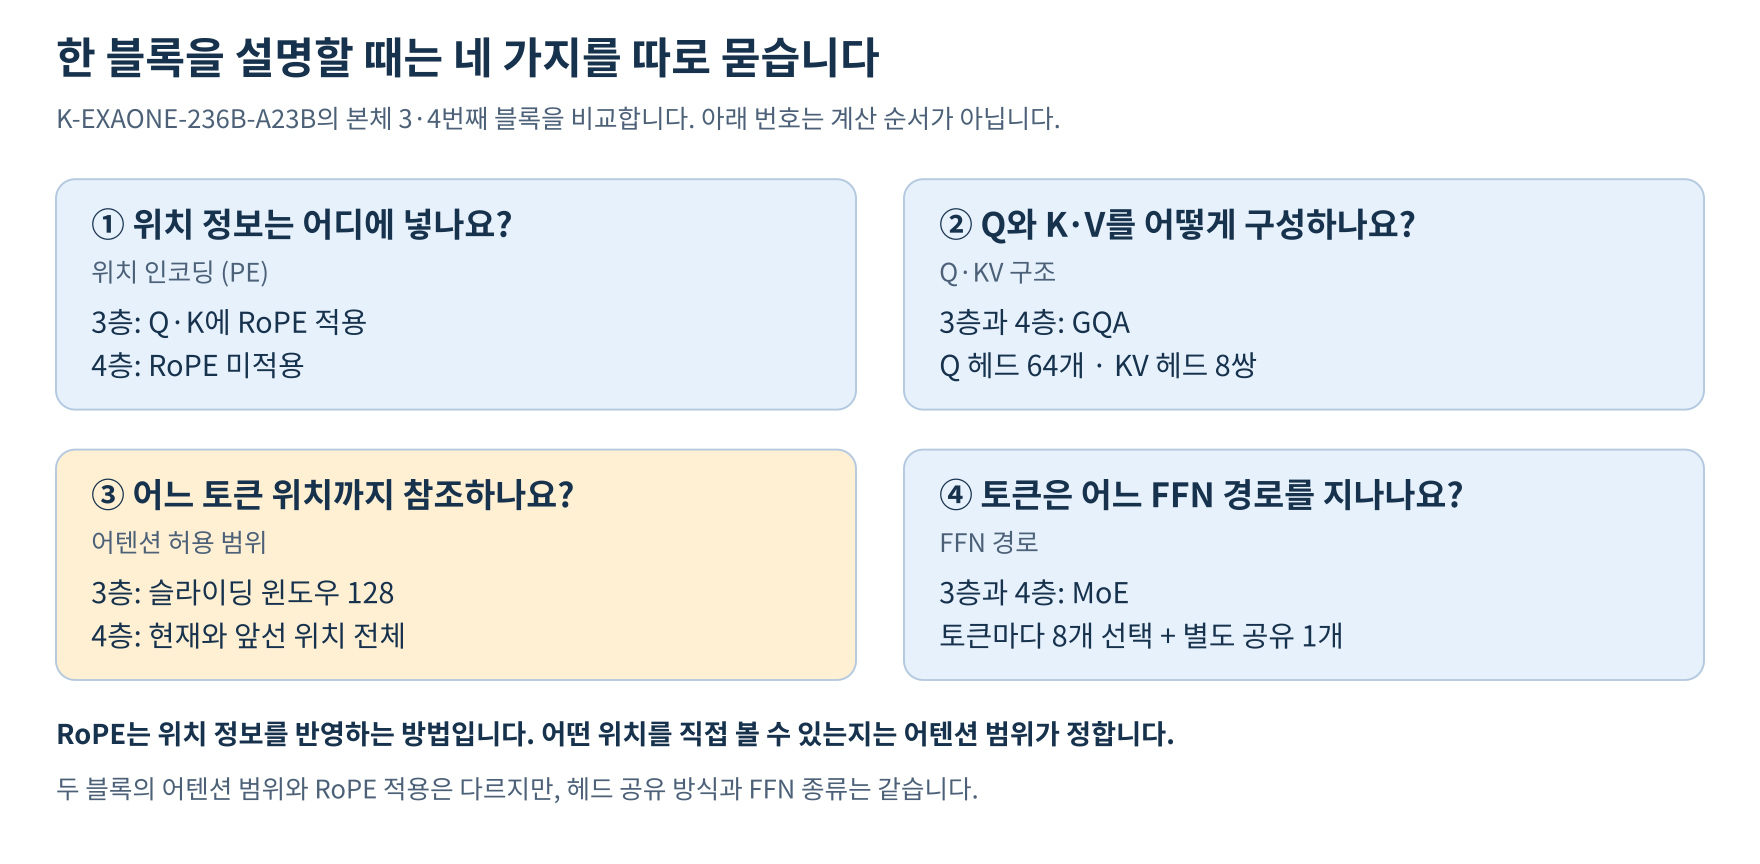

**그림 설명:** 3·4번째 블록 모두 GQA와 MoE를 사용합니다. 직접 참조 범위는 다르고, RoPE는 이 모델의 슬라이딩 윈도우 층에서만 적용합니다. 네 질문의 번호는 계산 순서가 아닙니다.


### 코드 설명: 원본 검증 후 같은 의미의 키를 읽기

`SOURCES`는 저장소·고정 revision·기준 SHA256입니다. `OFFLINE_CONFIG`는 교재에 함께 담은 공식 `config.json` **전체 바이트**입니다. `base64.b64decode`로 바이트를 복원한 뒤 SHA256이 다르면 중단합니다. 일치할 때만 `json.loads`로 사전을 만들고 모델 유형·층 수·Q 헤드 수·표현 폭을 읽습니다.

`pick`은 실제로 있는 별칭 키를 찾고, `show`는 키가 없는 경우의 **설정 미표기**와 값이 기록된 `null`·`false`·`0`을 구별합니다. 이 코드는 공식 원본을 오프라인에서 재현하는 방법입니다. 최신 변경 사항을 조회하거나 모델을 생성하지 않습니다.


### 무엇을 확인하나요?

출력에 저장소·revision·복원 바이트의 SHA256이 나타납니다. 일치 검사는 파일의 동일성을 확인하지만 모델 동작이나 정확도를 시험하지 않습니다. 이후 두 셀은 이때 만든 `configs`를 재사용합니다.


In [1]:
import base64
from collections import Counter
import hashlib
import json

# 각 항목은 (공식 저장소, 고정 revision, 그 config.json 전체 바이트의 기준 SHA256)입니다.
# 캐시 원본은 끝줄·공백도 보존하여 Base64로 내장합니다. 모델 가중치가 아닙니다.
SOURCES = {'GPT-2': ('openai-community/gpt2',
           '607a30d783dfa663caf39e06633721c8d4cfcd7e',
           '0daed7749b4f02b8f76240d5444551d7b08712dab4d0adb8239c56ba823bb7b4'),
 'Qwen3-4B': ('Qwen/Qwen3-4B',
              '1cfa9a7208912126459214e8b04321603b3df60c',
              '8ba006f74fecfaaeb392872a60f4a480e7ec9860153d2e1b769ec81f9a147f8a'),
 'DeepSeek-V3': ('deepseek-ai/DeepSeek-V3',
                 'e815299b0bcbac849fa540c768ef21845365c9eb',
                 'cbf0b95dc614de208a109bb5fd4e7eed11385e9c68411d2c17db5319443035d9'),
 'K-EXAONE-236B-A23B': ('LGAI-EXAONE/K-EXAONE-236B-A23B',
                        '61e6d578eb102b578e5704e2916ac841df9eca0a',
                        'afcc4355b0a504a1ea3333cda7217b63ff153560fccfa1c1718f681fbb8d4d8b')}

OFFLINE_CONFIG = {'GPT-2': 'ewogICJhY3RpdmF0aW9uX2Z1bmN0aW9uIjogImdlbHVfbmV3IiwKICAiYXJjaGl0ZWN0dXJlcyI6IFsKICAgICJHUFQyTE1IZWFkTW9kZWwiCiAgXSwKICAiYXR0bl9wZHJvcCI6IDAuMSwKICAiYm9zX3Rva2VuX2lkIjogNTAyNTYsCiAgImVtYmRfcGRyb3AiOiAwLjEsCiAgImVvc190b2tlbl9pZCI6IDUwMjU2LAogICJpbml0aWFsaXplcl9yYW5nZSI6IDAuMDIsCiAgImxheWVyX25vcm1fZXBzaWxvbiI6IDFlLTA1LAogICJtb2RlbF90eXBlIjogImdwdDIiLAogICJuX2N0eCI6IDEwMjQsCiAgIm5fZW1iZCI6IDc2OCwKICAibl9oZWFkIjogMTIsCiAgIm5fbGF5ZXIiOiAxMiwKICAibl9wb3NpdGlvbnMiOiAxMDI0LAogICJyZXNpZF9wZHJvcCI6IDAuMSwKICAic3VtbWFyeV9hY3RpdmF0aW9uIjogbnVsbCwKICAic3VtbWFyeV9maXJzdF9kcm9wb3V0IjogMC4xLAogICJzdW1tYXJ5X3Byb2pfdG9fbGFiZWxzIjogdHJ1ZSwKICAic3VtbWFyeV90eXBlIjogImNsc19pbmRleCIsCiAgInN1bW1hcnlfdXNlX3Byb2oiOiB0cnVlLAogICJ0YXNrX3NwZWNpZmljX3BhcmFtcyI6IHsKICAgICJ0ZXh0LWdlbmVyYXRpb24iOiB7CiAgICAgICJkb19zYW1wbGUiOiB0cnVlLAogICAgICAibWF4X2xlbmd0aCI6IDUwCiAgICB9CiAgfSwKICAidm9jYWJfc2l6ZSI6IDUwMjU3Cn0=',
 'Qwen3-4B': 'ewogICJhcmNoaXRlY3R1cmVzIjogWwogICAgIlF3ZW4zRm9yQ2F1c2FsTE0iCiAgXSwKICAiYXR0ZW50aW9uX2JpYXMiOiBmYWxzZSwKICAiYXR0ZW50aW9uX2Ryb3BvdXQiOiAwLjAsCiAgImJvc190b2tlbl9pZCI6IDE1MTY0MywKICAiZW9zX3Rva2VuX2lkIjogMTUxNjQ1LAogICJoZWFkX2RpbSI6IDEyOCwKICAiaGlkZGVuX2FjdCI6ICJzaWx1IiwKICAiaGlkZGVuX3NpemUiOiAyNTYwLAogICJpbml0aWFsaXplcl9yYW5nZSI6IDAuMDIsCiAgImludGVybWVkaWF0ZV9zaXplIjogOTcyOCwKICAibWF4X3Bvc2l0aW9uX2VtYmVkZGluZ3MiOiA0MDk2MCwKICAibWF4X3dpbmRvd19sYXllcnMiOiAzNiwKICAibW9kZWxfdHlwZSI6ICJxd2VuMyIsCiAgIm51bV9hdHRlbnRpb25faGVhZHMiOiAzMiwKICAibnVtX2hpZGRlbl9sYXllcnMiOiAzNiwKICAibnVtX2tleV92YWx1ZV9oZWFkcyI6IDgsCiAgInJtc19ub3JtX2VwcyI6IDFlLTA2LAogICJyb3BlX3NjYWxpbmciOiBudWxsLAogICJyb3BlX3RoZXRhIjogMTAwMDAwMCwKICAic2xpZGluZ193aW5kb3ciOiBudWxsLAogICJ0aWVfd29yZF9lbWJlZGRpbmdzIjogdHJ1ZSwKICAidG9yY2hfZHR5cGUiOiAiYmZsb2F0MTYiLAogICJ0cmFuc2Zvcm1lcnNfdmVyc2lvbiI6ICI0LjUxLjAiLAogICJ1c2VfY2FjaGUiOiB0cnVlLAogICJ1c2Vfc2xpZGluZ193aW5kb3ciOiBmYWxzZSwKICAidm9jYWJfc2l6ZSI6IDE1MTkzNgp9',
 'DeepSeek-V3': 'ewogICJhcmNoaXRlY3R1cmVzIjogWwogICAgIkRlZXBzZWVrVjNGb3JDYXVzYWxMTSIKICBdLAogICJhdHRlbnRpb25fYmlhcyI6IGZhbHNlLAogICJhdHRlbnRpb25fZHJvcG91dCI6IDAuMCwKICAiYXV0b19tYXAiOiB7CiAgICAiQXV0b0NvbmZpZyI6ICJjb25maWd1cmF0aW9uX2RlZXBzZWVrLkRlZXBzZWVrVjNDb25maWciLAogICAgIkF1dG9Nb2RlbCI6ICJtb2RlbGluZ19kZWVwc2Vlay5EZWVwc2Vla1YzTW9kZWwiLAogICAgIkF1dG9Nb2RlbEZvckNhdXNhbExNIjogIm1vZGVsaW5nX2RlZXBzZWVrLkRlZXBzZWVrVjNGb3JDYXVzYWxMTSIKICB9LAogICJib3NfdG9rZW5faWQiOiAwLAogICJlb3NfdG9rZW5faWQiOiAxLAogICJlcF9zaXplIjogMSwKICAiZmlyc3Rfa19kZW5zZV9yZXBsYWNlIjogMywKICAiaGlkZGVuX2FjdCI6ICJzaWx1IiwKICAiaGlkZGVuX3NpemUiOiA3MTY4LAogICJpbml0aWFsaXplcl9yYW5nZSI6IDAuMDIsCiAgImludGVybWVkaWF0ZV9zaXplIjogMTg0MzIsCiAgImt2X2xvcmFfcmFuayI6IDUxMiwKICAibWF4X3Bvc2l0aW9uX2VtYmVkZGluZ3MiOiAxNjM4NDAsCiAgIm1vZGVsX3R5cGUiOiAiZGVlcHNlZWtfdjMiLAogICJtb2VfaW50ZXJtZWRpYXRlX3NpemUiOiAyMDQ4LAogICJtb2VfbGF5ZXJfZnJlcSI6IDEsCiAgIm5fZ3JvdXAiOiA4LAogICJuX3JvdXRlZF9leHBlcnRzIjogMjU2LAogICJuX3NoYXJlZF9leHBlcnRzIjogMSwKICAibm9ybV90b3BrX3Byb2IiOiB0cnVlLAogICJudW1fYXR0ZW50aW9uX2hlYWRzIjogMTI4LAogICJudW1fZXhwZXJ0c19wZXJfdG9rIjogOCwKICAibnVtX2hpZGRlbl9sYXllcnMiOiA2MSwKICAibnVtX2tleV92YWx1ZV9oZWFkcyI6IDEyOCwKICAibnVtX25leHRuX3ByZWRpY3RfbGF5ZXJzIjogMSwKICAicV9sb3JhX3JhbmsiOiAxNTM2LAogICJxa19ub3BlX2hlYWRfZGltIjogMTI4LAogICJxa19yb3BlX2hlYWRfZGltIjogNjQsCiAgInF1YW50aXphdGlvbl9jb25maWciOiB7CiAgICAiYWN0aXZhdGlvbl9zY2hlbWUiOiAiZHluYW1pYyIsCiAgICAiZm10IjogImU0bTMiLAogICAgInF1YW50X21ldGhvZCI6ICJmcDgiLAogICAgIndlaWdodF9ibG9ja19zaXplIjogWwogICAgICAxMjgsCiAgICAgIDEyOAogICAgXQogIH0sCiAgInJtc19ub3JtX2VwcyI6IDFlLTA2LAogICJyb3BlX3NjYWxpbmciOiB7CiAgICAiYmV0YV9mYXN0IjogMzIsCiAgICAiYmV0YV9zbG93IjogMSwKICAgICJmYWN0b3IiOiA0MCwKICAgICJtc2NhbGUiOiAxLjAsCiAgICAibXNjYWxlX2FsbF9kaW0iOiAxLjAsCiAgICAib3JpZ2luYWxfbWF4X3Bvc2l0aW9uX2VtYmVkZGluZ3MiOiA0MDk2LAogICAgInR5cGUiOiAieWFybiIKICB9LAogICJyb3BlX3RoZXRhIjogMTAwMDAsCiAgInJvdXRlZF9zY2FsaW5nX2ZhY3RvciI6IDIuNSwKICAic2NvcmluZ19mdW5jIjogInNpZ21vaWQiLAogICJ0aWVfd29yZF9lbWJlZGRpbmdzIjogZmFsc2UsCiAgInRvcGtfZ3JvdXAiOiA0LAogICJ0b3BrX21ldGhvZCI6ICJub2F1eF90YyIsCiAgInRvcmNoX2R0eXBlIjogImJmbG9hdDE2IiwKICAidHJhbnNmb3JtZXJzX3ZlcnNpb24iOiAiNC4zMy4xIiwKICAidXNlX2NhY2hlIjogdHJ1ZSwKICAidl9oZWFkX2RpbSI6IDEyOCwKICAidm9jYWJfc2l6ZSI6IDEyOTI4MAp9Cg==',
 'K-EXAONE-236B-A23B': 'ewogICJhcmNoaXRlY3R1cmVzIjogWwogICAgIkV4YW9uZU1vZUZvckNhdXNhbExNIgogIF0sCiAgImF0dGVudGlvbl9kcm9wb3V0IjogMC4wLAogICJib3NfdG9rZW5faWQiOiAxLAogICJkdHlwZSI6ICJiZmxvYXQxNiIsCiAgImVvc190b2tlbl9pZCI6IDUzLAogICJmaXJzdF9rX2RlbnNlX3JlcGxhY2UiOiAxLAogICJoZWFkX2RpbSI6IDEyOCwKICAiaGlkZGVuX2FjdCI6ICJzaWx1IiwKICAiaGlkZGVuX3NpemUiOiA2MTQ0LAogICJpbml0aWFsaXplcl9yYW5nZSI6IDAuMDIsCiAgImludGVybWVkaWF0ZV9zaXplIjogMTg0MzIsCiAgImlzX21vZV9sYXllciI6IFsKICAgIGZhbHNlLAogICAgdHJ1ZSwKICAgIHRydWUsCiAgICB0cnVlLAogICAgdHJ1ZSwKICAgIHRydWUsCiAgICB0cnVlLAogICAgdHJ1ZSwKICAgIHRydWUsCiAgICB0cnVlLAogICAgdHJ1ZSwKICAgIHRydWUsCiAgICB0cnVlLAogICAgdHJ1ZSwKICAgIHRydWUsCiAgICB0cnVlLAogICAgdHJ1ZSwKICAgIHRydWUsCiAgICB0cnVlLAogICAgdHJ1ZSwKICAgIHRydWUsCiAgICB0cnVlLAogICAgdHJ1ZSwKICAgIHRydWUsCiAgICB0cnVlLAogICAgdHJ1ZSwKICAgIHRydWUsCiAgICB0cnVlLAogICAgdHJ1ZSwKICAgIHRydWUsCiAgICB0cnVlLAogICAgdHJ1ZSwKICAgIHRydWUsCiAgICB0cnVlLAogICAgdHJ1ZSwKICAgIHRydWUsCiAgICB0cnVlLAogICAgdHJ1ZSwKICAgIHRydWUsCiAgICB0cnVlLAogICAgdHJ1ZSwKICAgIHRydWUsCiAgICB0cnVlLAogICAgdHJ1ZSwKICAgIHRydWUsCiAgICB0cnVlLAogICAgdHJ1ZSwKICAgIHRydWUKICBdLAogICJsYXllcl90eXBlcyI6IFsKICAgICJzbGlkaW5nX2F0dGVudGlvbiIsCiAgICAic2xpZGluZ19hdHRlbnRpb24iLAogICAgInNsaWRpbmdfYXR0ZW50aW9uIiwKICAgICJmdWxsX2F0dGVudGlvbiIsCiAgICAic2xpZGluZ19hdHRlbnRpb24iLAogICAgInNsaWRpbmdfYXR0ZW50aW9uIiwKICAgICJzbGlkaW5nX2F0dGVudGlvbiIsCiAgICAiZnVsbF9hdHRlbnRpb24iLAogICAgInNsaWRpbmdfYXR0ZW50aW9uIiwKICAgICJzbGlkaW5nX2F0dGVudGlvbiIsCiAgICAic2xpZGluZ19hdHRlbnRpb24iLAogICAgImZ1bGxfYXR0ZW50aW9uIiwKICAgICJzbGlkaW5nX2F0dGVudGlvbiIsCiAgICAic2xpZGluZ19hdHRlbnRpb24iLAogICAgInNsaWRpbmdfYXR0ZW50aW9uIiwKICAgICJmdWxsX2F0dGVudGlvbiIsCiAgICAic2xpZGluZ19hdHRlbnRpb24iLAogICAgInNsaWRpbmdfYXR0ZW50aW9uIiwKICAgICJzbGlkaW5nX2F0dGVudGlvbiIsCiAgICAiZnVsbF9hdHRlbnRpb24iLAogICAgInNsaWRpbmdfYXR0ZW50aW9uIiwKICAgICJzbGlkaW5nX2F0dGVudGlvbiIsCiAgICAic2xpZGluZ19hdHRlbnRpb24iLAogICAgImZ1bGxfYXR0ZW50aW9uIiwKICAgICJzbGlkaW5nX2F0dGVudGlvbiIsCiAgICAic2xpZGluZ19hdHRlbnRpb24iLAogICAgInNsaWRpbmdfYXR0ZW50aW9uIiwKICAgICJmdWxsX2F0dGVudGlvbiIsCiAgICAic2xpZGluZ19hdHRlbnRpb24iLAogICAgInNsaWRpbmdfYXR0ZW50aW9uIiwKICAgICJzbGlkaW5nX2F0dGVudGlvbiIsCiAgICAiZnVsbF9hdHRlbnRpb24iLAogICAgInNsaWRpbmdfYXR0ZW50aW9uIiwKICAgICJzbGlkaW5nX2F0dGVudGlvbiIsCiAgICAic2xpZGluZ19hdHRlbnRpb24iLAogICAgImZ1bGxfYXR0ZW50aW9uIiwKICAgICJzbGlkaW5nX2F0dGVudGlvbiIsCiAgICAic2xpZGluZ19hdHRlbnRpb24iLAogICAgInNsaWRpbmdfYXR0ZW50aW9uIiwKICAgICJmdWxsX2F0dGVudGlvbiIsCiAgICAic2xpZGluZ19hdHRlbnRpb24iLAogICAgInNsaWRpbmdfYXR0ZW50aW9uIiwKICAgICJzbGlkaW5nX2F0dGVudGlvbiIsCiAgICAiZnVsbF9hdHRlbnRpb24iLAogICAgInNsaWRpbmdfYXR0ZW50aW9uIiwKICAgICJzbGlkaW5nX2F0dGVudGlvbiIsCiAgICAic2xpZGluZ19hdHRlbnRpb24iLAogICAgImZ1bGxfYXR0ZW50aW9uIgogIF0sCiAgIm1heF9wb3NpdGlvbl9lbWJlZGRpbmdzIjogMjYyMTQ0LAogICJtbHBfbGF5ZXJfdHlwZXMiOiBbCiAgICAiZGVuc2UiLAogICAgInNwYXJzZSIsCiAgICAic3BhcnNlIiwKICAgICJzcGFyc2UiLAogICAgInNwYXJzZSIsCiAgICAic3BhcnNlIiwKICAgICJzcGFyc2UiLAogICAgInNwYXJzZSIsCiAgICAic3BhcnNlIiwKICAgICJzcGFyc2UiLAogICAgInNwYXJzZSIsCiAgICAic3BhcnNlIiwKICAgICJzcGFyc2UiLAogICAgInNwYXJzZSIsCiAgICAic3BhcnNlIiwKICAgICJzcGFyc2UiLAogICAgInNwYXJzZSIsCiAgICAic3BhcnNlIiwKICAgICJzcGFyc2UiLAogICAgInNwYXJzZSIsCiAgICAic3BhcnNlIiwKICAgICJzcGFyc2UiLAogICAgInNwYXJzZSIsCiAgICAic3BhcnNlIiwKICAgICJzcGFyc2UiLAogICAgInNwYXJzZSIsCiAgICAic3BhcnNlIiwKICAgICJzcGFyc2UiLAogICAgInNwYXJzZSIsCiAgICAic3BhcnNlIiwKICAgICJzcGFyc2UiLAogICAgInNwYXJzZSIsCiAgICAic3BhcnNlIiwKICAgICJzcGFyc2UiLAogICAgInNwYXJzZSIsCiAgICAic3BhcnNlIiwKICAgICJzcGFyc2UiLAogICAgInNwYXJzZSIsCiAgICAic3BhcnNlIiwKICAgICJzcGFyc2UiLAogICAgInNwYXJzZSIsCiAgICAic3BhcnNlIiwKICAgICJzcGFyc2UiLAogICAgInNwYXJzZSIsCiAgICAic3BhcnNlIiwKICAgICJzcGFyc2UiLAogICAgInNwYXJzZSIsCiAgICAic3BhcnNlIgogIF0sCiAgIm1vZGVsX3R5cGUiOiAiZXhhb25lX21vZSIsCiAgIm1vZV9pbnRlcm1lZGlhdGVfc2l6ZSI6IDIwNDgsCiAgIm10cF9sYXllcl90eXBlcyI6IFsKICAgICJmdWxsX2F0dGVudGlvbiIKICBdLAogICJtdHBfc2xpZGluZ193aW5kb3dzIjogWwogICAgMAogIF0sCiAgIm5fZ3JvdXAiOiAxLAogICJub3JtX3RvcGtfcHJvYiI6IHRydWUsCiAgIm51bV9hdHRlbnRpb25faGVhZHMiOiA2NCwKICAibnVtX2V4cGVydHMiOiAxMjgsCiAgIm51bV9leHBlcnRzX3Blcl90b2siOiA4LAogICJudW1faGlkZGVuX2xheWVycyI6IDQ4LAogICJudW1fa2V5X3ZhbHVlX2hlYWRzIjogOCwKICAibnVtX25leHRuX3ByZWRpY3RfbGF5ZXJzIjogMSwKICAibnVtX3NoYXJlZF9leHBlcnRzIjogMSwKICAicGFkX3Rva2VuX2lkIjogMCwKICAicm1zX25vcm1fZXBzIjogMWUtMDUsCiAgInJvcGVfcGFyYW1ldGVycyI6IHsKICAgICJyb3BlX3RoZXRhIjogMTAwMDAwMCwKICAgICJyb3BlX3R5cGUiOiAiZGVmYXVsdCIKICB9LAogICJyb3V0ZWRfc2NhbGluZ19mYWN0b3IiOiAyLjUsCiAgInNjb3JpbmdfZnVuYyI6ICJzaWdtb2lkIiwKICAic2xpZGluZ193aW5kb3ciOiAxMjgsCiAgInNsaWRpbmdfd2luZG93X3BhdHRlcm4iOiAiTExMRyIsCiAgInNsaWRpbmdfd2luZG93cyI6IFsKICAgIDEyOCwKICAgIDEyOCwKICAgIDEyOCwKICAgIDAsCiAgICAxMjgsCiAgICAxMjgsCiAgICAxMjgsCiAgICAwLAogICAgMTI4LAogICAgMTI4LAogICAgMTI4LAogICAgMCwKICAgIDEyOCwKICAgIDEyOCwKICAgIDEyOCwKICAgIDAsCiAgICAxMjgsCiAgICAxMjgsCiAgICAxMjgsCiAgICAwLAogICAgMTI4LAogICAgMTI4LAogICAgMTI4LAogICAgMCwKICAgIDEyOCwKICAgIDEyOCwKICAgIDEyOCwKICAgIDAsCiAgICAxMjgsCiAgICAxMjgsCiAgICAxMjgsCiAgICAwLAogICAgMTI4LAogICAgMTI4LAogICAgMTI4LAogICAgMCwKICAgIDEyOCwKICAgIDEyOCwKICAgIDEyOCwKICAgIDAsCiAgICAxMjgsCiAgICAxMjgsCiAgICAxMjgsCiAgICAwLAogICAgMTI4LAogICAgMTI4LAogICAgMTI4LAogICAgMAogIF0sCiAgInRpZV93b3JkX2VtYmVkZGluZ3MiOiBmYWxzZSwKICAidG9rZW5pemVyX2NsYXNzIjogIkdQVDJUb2tlbml6ZXIiLAogICJ0b3BrX2dyb3VwIjogMSwKICAidHJhbnNmb3JtZXJzX3ZlcnNpb24iOiAiNS4xLjAiLAogICJ1c2VfY2FjaGUiOiB0cnVlLAogICJ2b2NhYl9zaXplIjogMTUzNjAwCn0K'}

MISSING = object()


def pick(config, *keys):
    """첫 번째 실제 키와 값. JSON null도 존재하는 값이므로 다음 키로 넘기지 않습니다."""
    return next(((key, config[key]) for key in keys if key in config), (None, MISSING))


def show(value):
    # 미표기, null, false, 0을 서로 다른 표현으로 표시합니다.
    return "설정 미표기" if value is MISSING else json.dumps(value, ensure_ascii=False)


def field(config, *keys):
    key, value = pick(config, *keys)
    return f"{key}={show(value)}" if key is not None else "설정 미표기"


configs = {}
for name, (repo, revision, expected_sha) in SOURCES.items():
    raw = base64.b64decode(OFFLINE_CONFIG[name], validate=True)
    observed = hashlib.sha256(raw).hexdigest()
    assert observed == expected_sha, f"원본 해시 불일치: {name}"
    configs[name] = json.loads(raw)
    print(f"{name} | {repo}@{revision}")
    print(f"  원본 SHA256: {observed}")
    config = configs[name]
    print("  " + " / ".join((field(config, "model_type"),
                              field(config, "num_hidden_layers", "n_layer"),
                              field(config, "num_attention_heads", "n_head"),
                              field(config, "hidden_size", "n_embd"))))
print("[PASS] 네 고정 config 원본의 SHA256 일치 및 JSON 읽기")


GPT-2 | openai-community/gpt2@607a30d783dfa663caf39e06633721c8d4cfcd7e
  원본 SHA256: 0daed7749b4f02b8f76240d5444551d7b08712dab4d0adb8239c56ba823bb7b4
  model_type="gpt2" / n_layer=12 / n_head=12 / n_embd=768
Qwen3-4B | Qwen/Qwen3-4B@1cfa9a7208912126459214e8b04321603b3df60c
  원본 SHA256: 8ba006f74fecfaaeb392872a60f4a480e7ec9860153d2e1b769ec81f9a147f8a
  model_type="qwen3" / num_hidden_layers=36 / num_attention_heads=32 / hidden_size=2560
DeepSeek-V3 | deepseek-ai/DeepSeek-V3@e815299b0bcbac849fa540c768ef21845365c9eb
  원본 SHA256: cbf0b95dc614de208a109bb5fd4e7eed11385e9c68411d2c17db5319443035d9
  model_type="deepseek_v3" / num_hidden_layers=61 / num_attention_heads=128 / hidden_size=7168
K-EXAONE-236B-A23B | LGAI-EXAONE/K-EXAONE-236B-A23B@61e6d578eb102b578e5704e2916ac841df9eca0a
  원본 SHA256: afcc4355b0a504a1ea3333cda7217b63ff153560fccfa1c1718f681fbb8d4d8b
  model_type="exaone_moe" / num_hidden_layers=48 / num_attention_heads=64 / hidden_size=6144
[PASS] 네 고정 config 원본의 SHA256 일치 및 JSON 읽기


### 출력 설명: 같은 질문에 답하는 서로 다른 키 이름

`n_layer`와 `num_hidden_layers`는 모두 본체의 블록 수, `n_head`와 `num_attention_heads`는 Query 헤드 수를 나타냅니다. 층을 나타내는 숫자와 토큰 표현의 성분 수는 서로 단위가 다릅니다. `model_type`은 구현을 찾는 단서이지 모델 실행 흔적이 아닙니다. 마지막 PASS는 설정 원본의 해시 검사와 JSON 읽기를 마쳤다는 뜻입니다.


## 2. 위치 정보, Q·KV 표현, 직접 읽는 범위 구분하기

- **GPT-2:** 별도 KV 헤드 수와 RoPE 키가 원본에 없습니다. 고정 Transformers [GPT-2 구현](https://github.com/huggingface/transformers/blob/v5.23.0/src/transformers/models/gpt2/modeling_gpt2.py)에서 MHA, 학습된 절대 위치 임베딩, 전체 범위 인과적 셀프 어텐션을 확인합니다. 미표기는 “KV가 없다”는 뜻이 아닙니다.
- **Qwen3-4B:** Q/KV 헤드가 나뉜 GQA이며 `use_sliding_window=false`입니다. `rope_theta`와 `rope_scaling`은 위치 정보를 다루는 설정입니다. 어텐션의 직접 범위 또는 FFN 종류와는 별개입니다. [Qwen3 보고서 §2: 모델 구조](https://arxiv.org/html/2505.09388#S2)
- **DeepSeek-V3:** `kv_lora_rank`는 MLA의 KV 잠재 표현 폭이고, `qk_rope_head_dim`은 회전하는 Q/K의 위치 성분 폭입니다. [DeepSeek-V3 보고서 §2.1](https://arxiv.org/html/2412.19437#S2.SS1)에서 두 경로의 차이를 확인할 수 있습니다. config에 윈도우 키가 없다는 것만으로 별도 위치 제한 유무를 단정하지 않습니다.
- **K-EXAONE:** 헤드 공유(GQA)와 슬라이딩 3층·전체 1층 반복을 함께 사용합니다. [K-EXAONE 보고서 §2.1](https://arxiv.org/html/2601.01739v2#S2.SS1)는 RoPE를 **슬라이딩 윈도우 층에만** 적용한다고 설명합니다. `rope_parameters`가 있다는 사실만으로 모든 층이 RoPE를 쓴다고 결론 내리지 않습니다.




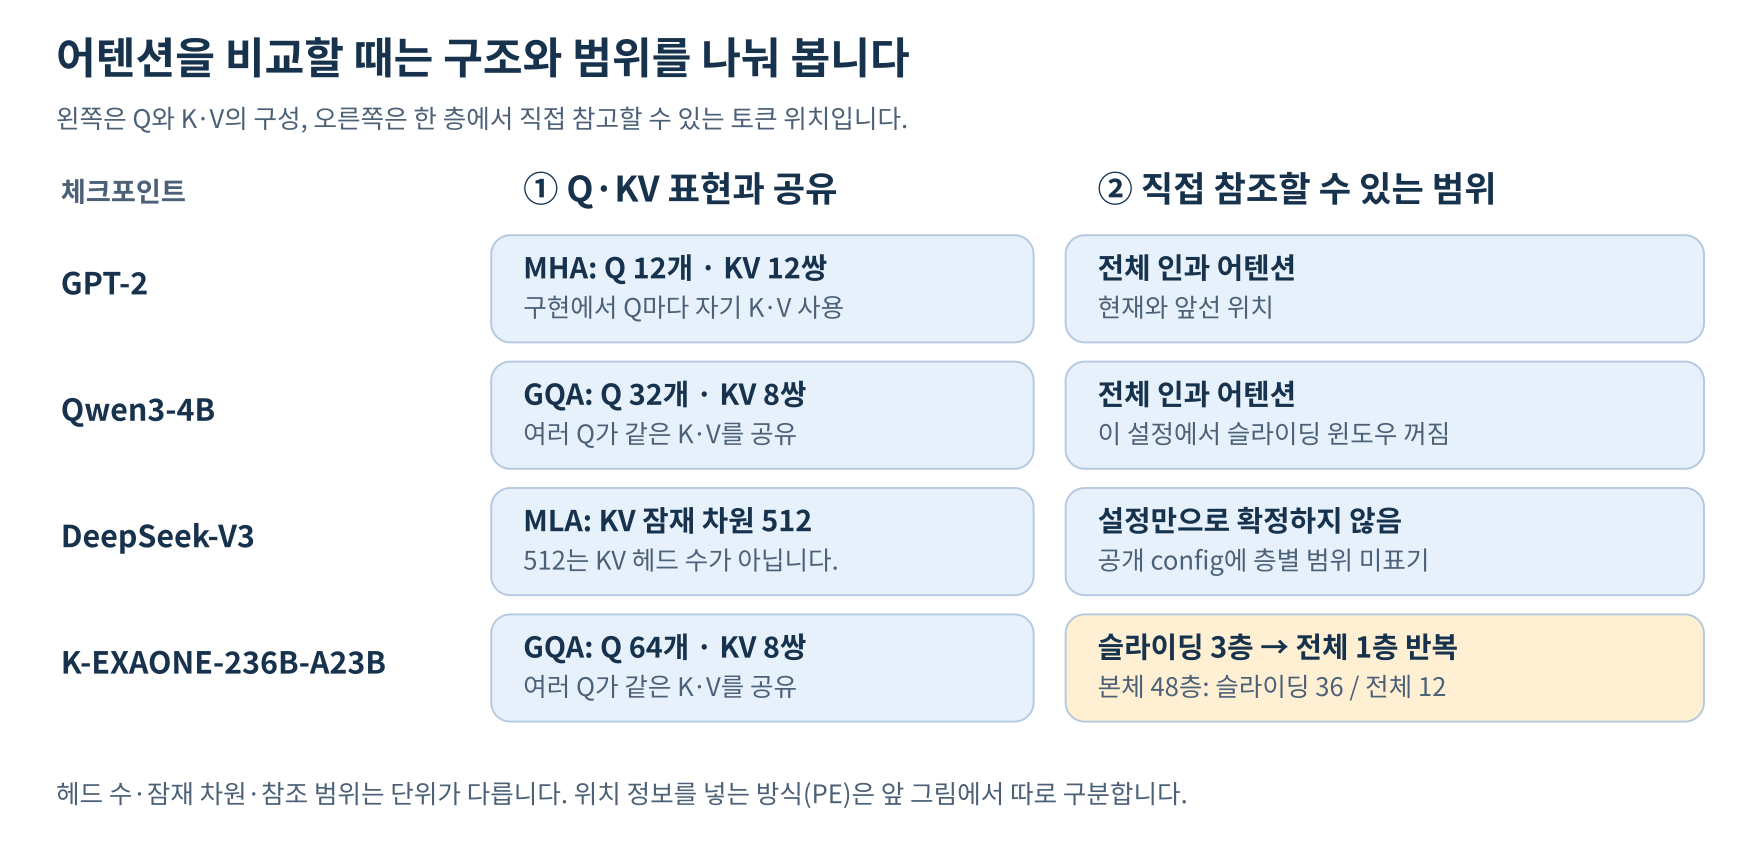

**그림 설명:** K-EXAONE의 Q 64·KV 8은 헤드 구성이고, 슬라이딩 36층·전체 12층은 범위의 층별 배치입니다. DeepSeek-V3의 512는 KV 잠재 표현의 폭으로, 헤드 수나 윈도우 크기가 아닙니다.


### 수치의 단위가 다르면 직접 비교하지 않습니다

Qwen3-4B의 KV 헤드 수, DeepSeek-V3의 잠재 벡터 성분 수, K-EXAONE의 윈도우 위치 수는 각각 다른 질문의 답입니다. Q 헤드 수를 KV 헤드 수로 나눠 그룹 크기를 계산할 수는 있지만, 그 결과를 실제 캐시 메모리 절감률이나 실행 속도로 환산하지 않습니다. 위치 범위 숫자는 모델 전체 문맥 길이와도 다릅니다.


### 코드 설명: 선언값과 계산값을 나누기

Q·KV 헤드 수, RoPE 관련 키, 윈도우 관련 키를 원본에서 읽습니다. Q·KV 수가 모두 있고 MLA가 아닌 경우에만 나눗셈으로 **그룹 크기**를 계산합니다. 층 종류 목록이 있는 경우 `Counter`로 개수를 세고, 전체 목록을 재현하는 가장 짧은 반복 단위를 찾습니다. `설정 미표기`나 `null`을 0으로 바꾸지 않습니다.


In [2]:
# 보이는 수치는 configs에서 읽거나 아래에서 계산합니다.
# Q/KV 비율은 비교용 산술이며 실제 메모리 절감률이 아닙니다.
for name, config in configs.items():
    print(name)
    _, query = pick(config, "num_attention_heads", "n_head")
    _, kv = pick(config, "num_key_value_heads")
    _, latent = pick(config, "kv_lora_rank")
    print(f"  Q 헤드: {show(query)} / KV 헤드 설정: {show(kv)} / KV 잠재 차원: {show(latent)}")
    # MLA에는 Q/KV 단순 비를 붙이지 않습니다. GPT-2의 KV 미표기도 계산하지 않습니다.
    if latent is MISSING and isinstance(query, int) and isinstance(kv, int) and kv > 0:
        assert query % kv == 0, f"Q 그룹을 균등 배치할 수 없음: {name}"
        print(f"  Q/KV 그룹 크기(계산): {query} ÷ {kv} = {query // kv}")
    _, nested_rope = pick(config, "rope_parameters")
    rope_cfg = nested_rope if isinstance(nested_rope, dict) else config
    print("  위치 설정: " + " / ".join((field(config, "max_position_embeddings", "n_positions"),
                                       field(rope_cfg, "rope_theta"), field(config, "qk_rope_head_dim"))))
    if "rope_scaling" in config or "rope_parameters" in config:
        print("  " + field(config, "rope_parameters", "rope_scaling"))
    print("  윈도우: " + field(config, "use_sliding_window") + " / " + field(config, "sliding_window"))
    types = config.get("layer_types")
    if isinstance(types, list):
        _, blocks = pick(config, "num_hidden_layers", "n_layer")
        assert len(types) == blocks, f"어텐션 목록 길이와 본체 층 수 불일치: {name}"
        period = next(k for k in range(1, len(types) + 1) if len(types) % k == 0
                      and types[:k] * (len(types) // k) == types)
        print(f"  층별 어텐션(집계): {dict(Counter(types))}")
        print(f"  반복 단위(계산): {types[:period]} × {len(types) // period}")
print("[PASS] 적용 가능한 그룹 크기·어텐션 목록 검사")


GPT-2
  Q 헤드: 12 / KV 헤드 설정: 설정 미표기 / KV 잠재 차원: 설정 미표기
  위치 설정: n_positions=1024 / 설정 미표기 / 설정 미표기
  윈도우: 설정 미표기 / 설정 미표기
Qwen3-4B
  Q 헤드: 32 / KV 헤드 설정: 8 / KV 잠재 차원: 설정 미표기
  Q/KV 그룹 크기(계산): 32 ÷ 8 = 4
  위치 설정: max_position_embeddings=40960 / rope_theta=1000000 / 설정 미표기
  rope_scaling=null
  윈도우: use_sliding_window=false / sliding_window=null
DeepSeek-V3
  Q 헤드: 128 / KV 헤드 설정: 128 / KV 잠재 차원: 512
  위치 설정: max_position_embeddings=163840 / rope_theta=10000 / qk_rope_head_dim=64
  rope_scaling={"beta_fast": 32, "beta_slow": 1, "factor": 40, "mscale": 1.0, "mscale_all_dim": 1.0, "original_max_position_embeddings": 4096, "type": "yarn"}
  윈도우: 설정 미표기 / 설정 미표기
K-EXAONE-236B-A23B
  Q 헤드: 64 / KV 헤드 설정: 8 / KV 잠재 차원: 설정 미표기
  Q/KV 그룹 크기(계산): 64 ÷ 8 = 8
  위치 설정: max_position_embeddings=262144 / rope_theta=1000000 / 설정 미표기
  rope_parameters={"rope_theta": 1000000, "rope_type": "default"}
  윈도우: 설정 미표기 / sliding_window=128
  층별 어텐션(집계): {'sliding_attention': 36, 'full_attention': 12}
  반복 단위(계

### 출력 설명: 그룹 크기·잠재 차원·윈도우는 다른 값입니다

- Qwen3-4B의 그룹 크기 4와 K-EXAONE의 그룹 크기 8은 각각 원본에서 읽은 Q/KV 헤드 수를 나눈 **계산값**입니다.
- DeepSeek-V3의 512와 64는 각각 KV 잠재 표현과 Q·K 회전 성분에 관한 **설정값**입니다. 어느 쪽도 토큰 위치 수가 아닙니다.
- K-EXAONE에서 36슬라이딩·12전체는 층 목록의 **집계**, 슬라이딩 3층 뒤 전체 1층은 그 **순서**입니다. 윈도우 128은 해당 층의 직접 참고 범위이며 현재를 포함합니다.

PASS는 유효한 그룹 크기와 명시된 층 목록의 길이 검사를 마쳤다는 뜻입니다. RoPE 적용 층과 GPT-2의 위치 임베딩 방식은 별도 구현·보고서에서 확인하며 이 셀에서 모델로 실행하지 않습니다.


## 3. 라우팅 전문가와 공유 전문가를 나누기

라우팅 전문가는 토큰별 선택 후보이고, 공유 전문가는 그 top-k 밖의 경로입니다. 토큰 하나가 고르는 전문가 수가 같아도 후보 수와 본체에서 MoE 층을 배치하는 방법은 다를 수 있습니다. 같은 블록의 어텐션 종류와 FFN 종류도 별개입니다.

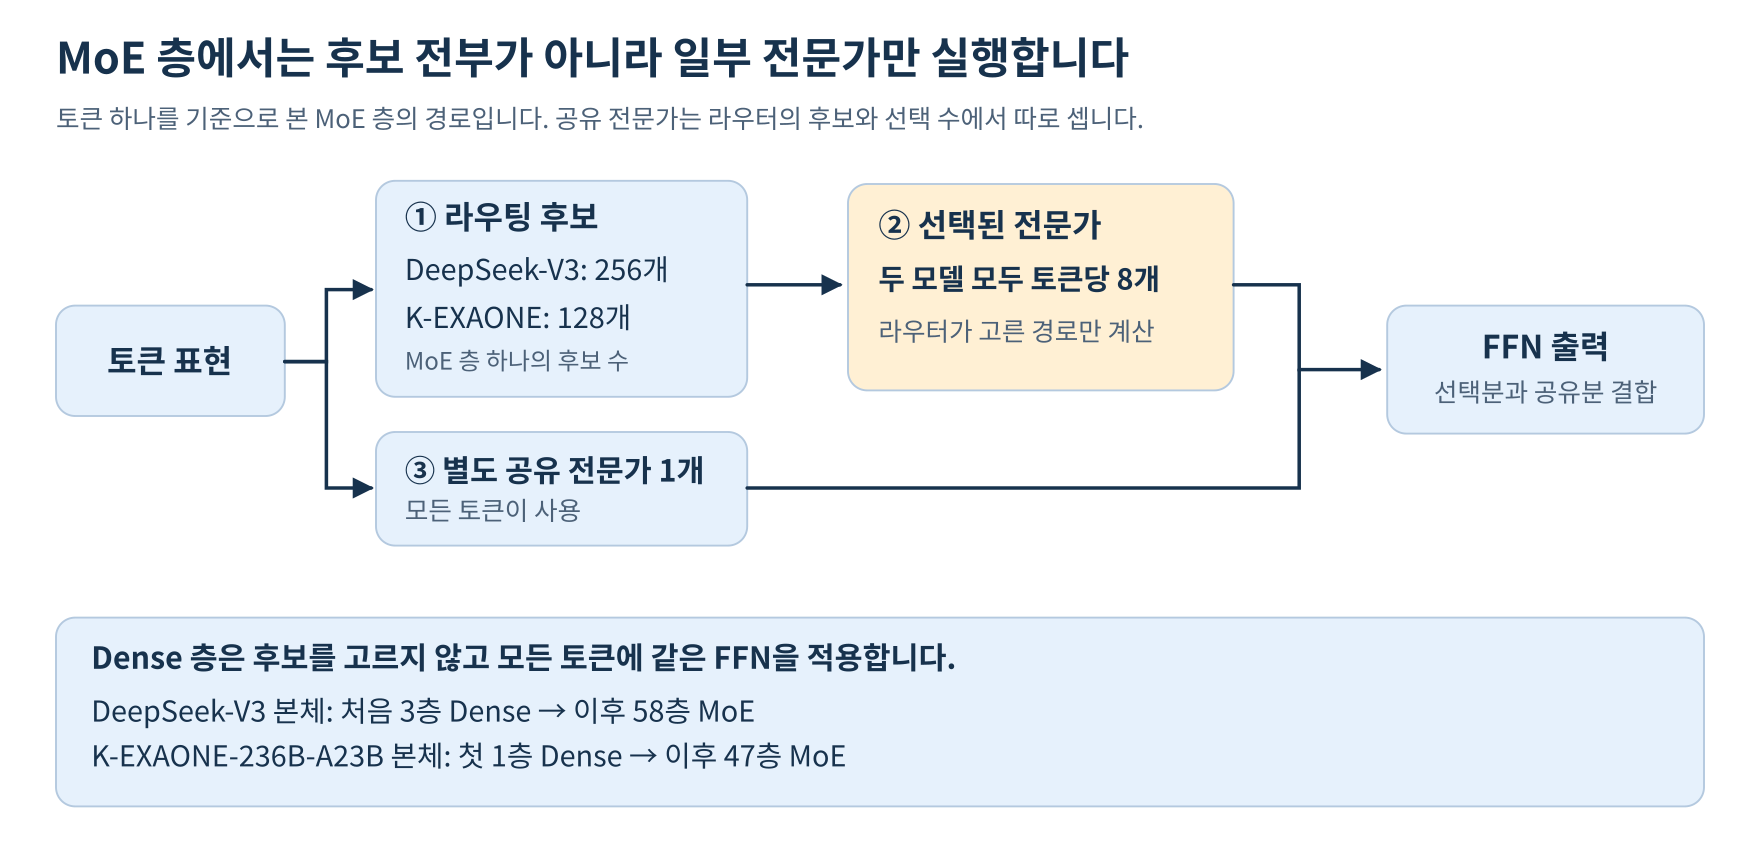

**그림 설명:** 후보를 모두 실행하는 것이 아닙니다. 두 MoE 모델 모두 라우터가 고른 8개의 출력과 별도 공유 전문가의 출력을 합칩니다. 첫 Dense 층에서는 라우터를 거치지 않습니다.


### FFN 목록과 FFN 배치 규칙을 구별합니다

K-EXAONE은 `mlp_layer_types`의 명시 목록으로 집계합니다. DeepSeek-V3는 처음 Dense 층 수와 `moe_layer_freq`의 배치 규칙을 읽어 이후 MoE 층 수를 계산합니다. GPT-2와 Qwen3-4B의 전문가 설정 미표시는 0을 읽었다는 뜻이 아닙니다. 두 모델의 Dense FFN 구조는 각각 구현과 보고서에서 확인합니다.


### 코드 설명: 세 전문가 수와 본체 FFN 배치 읽기

각 저장소의 다른 키 이름을 후보·선택·공유로 나란히 표시합니다. `Counter`는 FFN 층의 종류를 세고, `layer_types[3]`와 `mlp_layer_types[3]`는 **0부터 세는 인덱스 3**, 즉 같은 본체 4번째 블록에서 어텐션과 FFN을 각각 확인합니다. DeepSeek-V3는 명시 목록 대신 `moe_layer_freq=1`을 적용해 처음 Dense 층 뒤의 MoE 층 수를 구합니다.


In [3]:
for name, config in configs.items():
    print(name)
    _, routed = pick(config, "n_routed_experts", "num_local_experts", "num_experts")
    _, selected = pick(config, "num_experts_per_tok", "experts_per_token")
    _, shared = pick(config, "n_shared_experts", "num_shared_experts")
    print(f"  라우팅 후보={show(routed)} / 토큰당 선택={show(selected)} / 공유={show(shared)}")
    if isinstance(routed, int) and isinstance(selected, int):
        assert 0 < selected <= routed, f"후보/선택 수 불일치: {name}"
    types = config.get("mlp_layer_types")
    _, blocks = pick(config, "num_hidden_layers", "n_layer")
    _, first_dense = pick(config, "first_k_dense_replace")
    if isinstance(types, list):
        assert len(types) == blocks, f"FFN 목록 길이와 본체 층 수 불일치: {name}"
        print(f"  FFN 층 종류(목록 집계): {dict(Counter(types))}")
        if isinstance(first_dense, int):
            assert types[:first_dense] == ["dense"] * first_dense and types.count("dense") == first_dense
        attention_types = config.get("layer_types")
        if isinstance(attention_types, list):
            assert len(attention_types) == len(types)
            print(f"  본체 4번째 블록: {attention_types[3]} 어텐션 + {types[3]} FFN")
    elif isinstance(first_dense, int):
        print(f"  처음 Dense: {first_dense}층 / 본체 층 수: {blocks} / moe_layer_freq: {show(config.get('moe_layer_freq', MISSING))}")
        # 반복 간격이 1이면 처음 Dense 뒤의 나머지 층은 모두 MoE라는 규칙을 적용합니다.
        if config.get("moe_layer_freq") == 1:
            assert 0 <= first_dense <= blocks
            print(f"  이후 MoE(설정 규칙 적용): {blocks} − {first_dense} = {blocks - first_dense}층")
print("[PASS] 전문가 수 및 명시된 본체 FFN 배치 검사 완료")


GPT-2
  라우팅 후보=설정 미표기 / 토큰당 선택=설정 미표기 / 공유=설정 미표기
Qwen3-4B
  라우팅 후보=설정 미표기 / 토큰당 선택=설정 미표기 / 공유=설정 미표기
DeepSeek-V3
  라우팅 후보=256 / 토큰당 선택=8 / 공유=1
  처음 Dense: 3층 / 본체 층 수: 61 / moe_layer_freq: 1
  이후 MoE(설정 규칙 적용): 61 − 3 = 58층
K-EXAONE-236B-A23B
  라우팅 후보=128 / 토큰당 선택=8 / 공유=1
  FFN 층 종류(목록 집계): {'dense': 1, 'sparse': 47}
  본체 4번째 블록: full_attention 어텐션 + sparse FFN
[PASS] 전문가 수 및 명시된 본체 FFN 배치 검사 완료


### 출력 설명: 두 MoE 모델의 ‘8개 선택’은 같은 구조를 뜻하지 않습니다

DeepSeek-V3는 처음 3개 Dense 뒤 나머지 58개 MoE, K-EXAONE은 첫 1개 Dense와 이후 47개 sparse FFN입니다. DeepSeek-V3의 58은 **규칙을 적용한 계산값**, K-EXAONE 47은 **목록 집계**입니다. 두 모델 모두 8개를 선택하지만 후보는 각각 256개와 128개이며, 공유 1개는 선택 8개 안에 포함시키지 않습니다. K-EXAONE 본체 4번째 블록의 `full_attention`과 `sparse`는 서로 다른 축입니다.

실제 입력으로 선택된 전문가 번호·가중치·답변 품질은 확인하지 않았습니다. PASS는 설정의 개수와 명시된 FFN 배치를 확인한 것입니다.


## 4. 네 모델의 전체 구조와 대표 블록 비교

앞에서 읽은 네 가지 선택을 실제 모델 구조에 다시 놓아 보세요. 각 그림의 왼쪽은 토큰 ID에서 다음 토큰 로짓까지의 경로, 오른쪽은 특정 본체 블록의 확대입니다. 확대에 표시한 블록이 모든 층과 똑같다고 가정하지 않습니다. 예를 들어 첫 Dense 층이 따로 있거나, 층마다 직접 읽는 위치의 범위가 달라질 수 있습니다.

### GPT-2 기본형

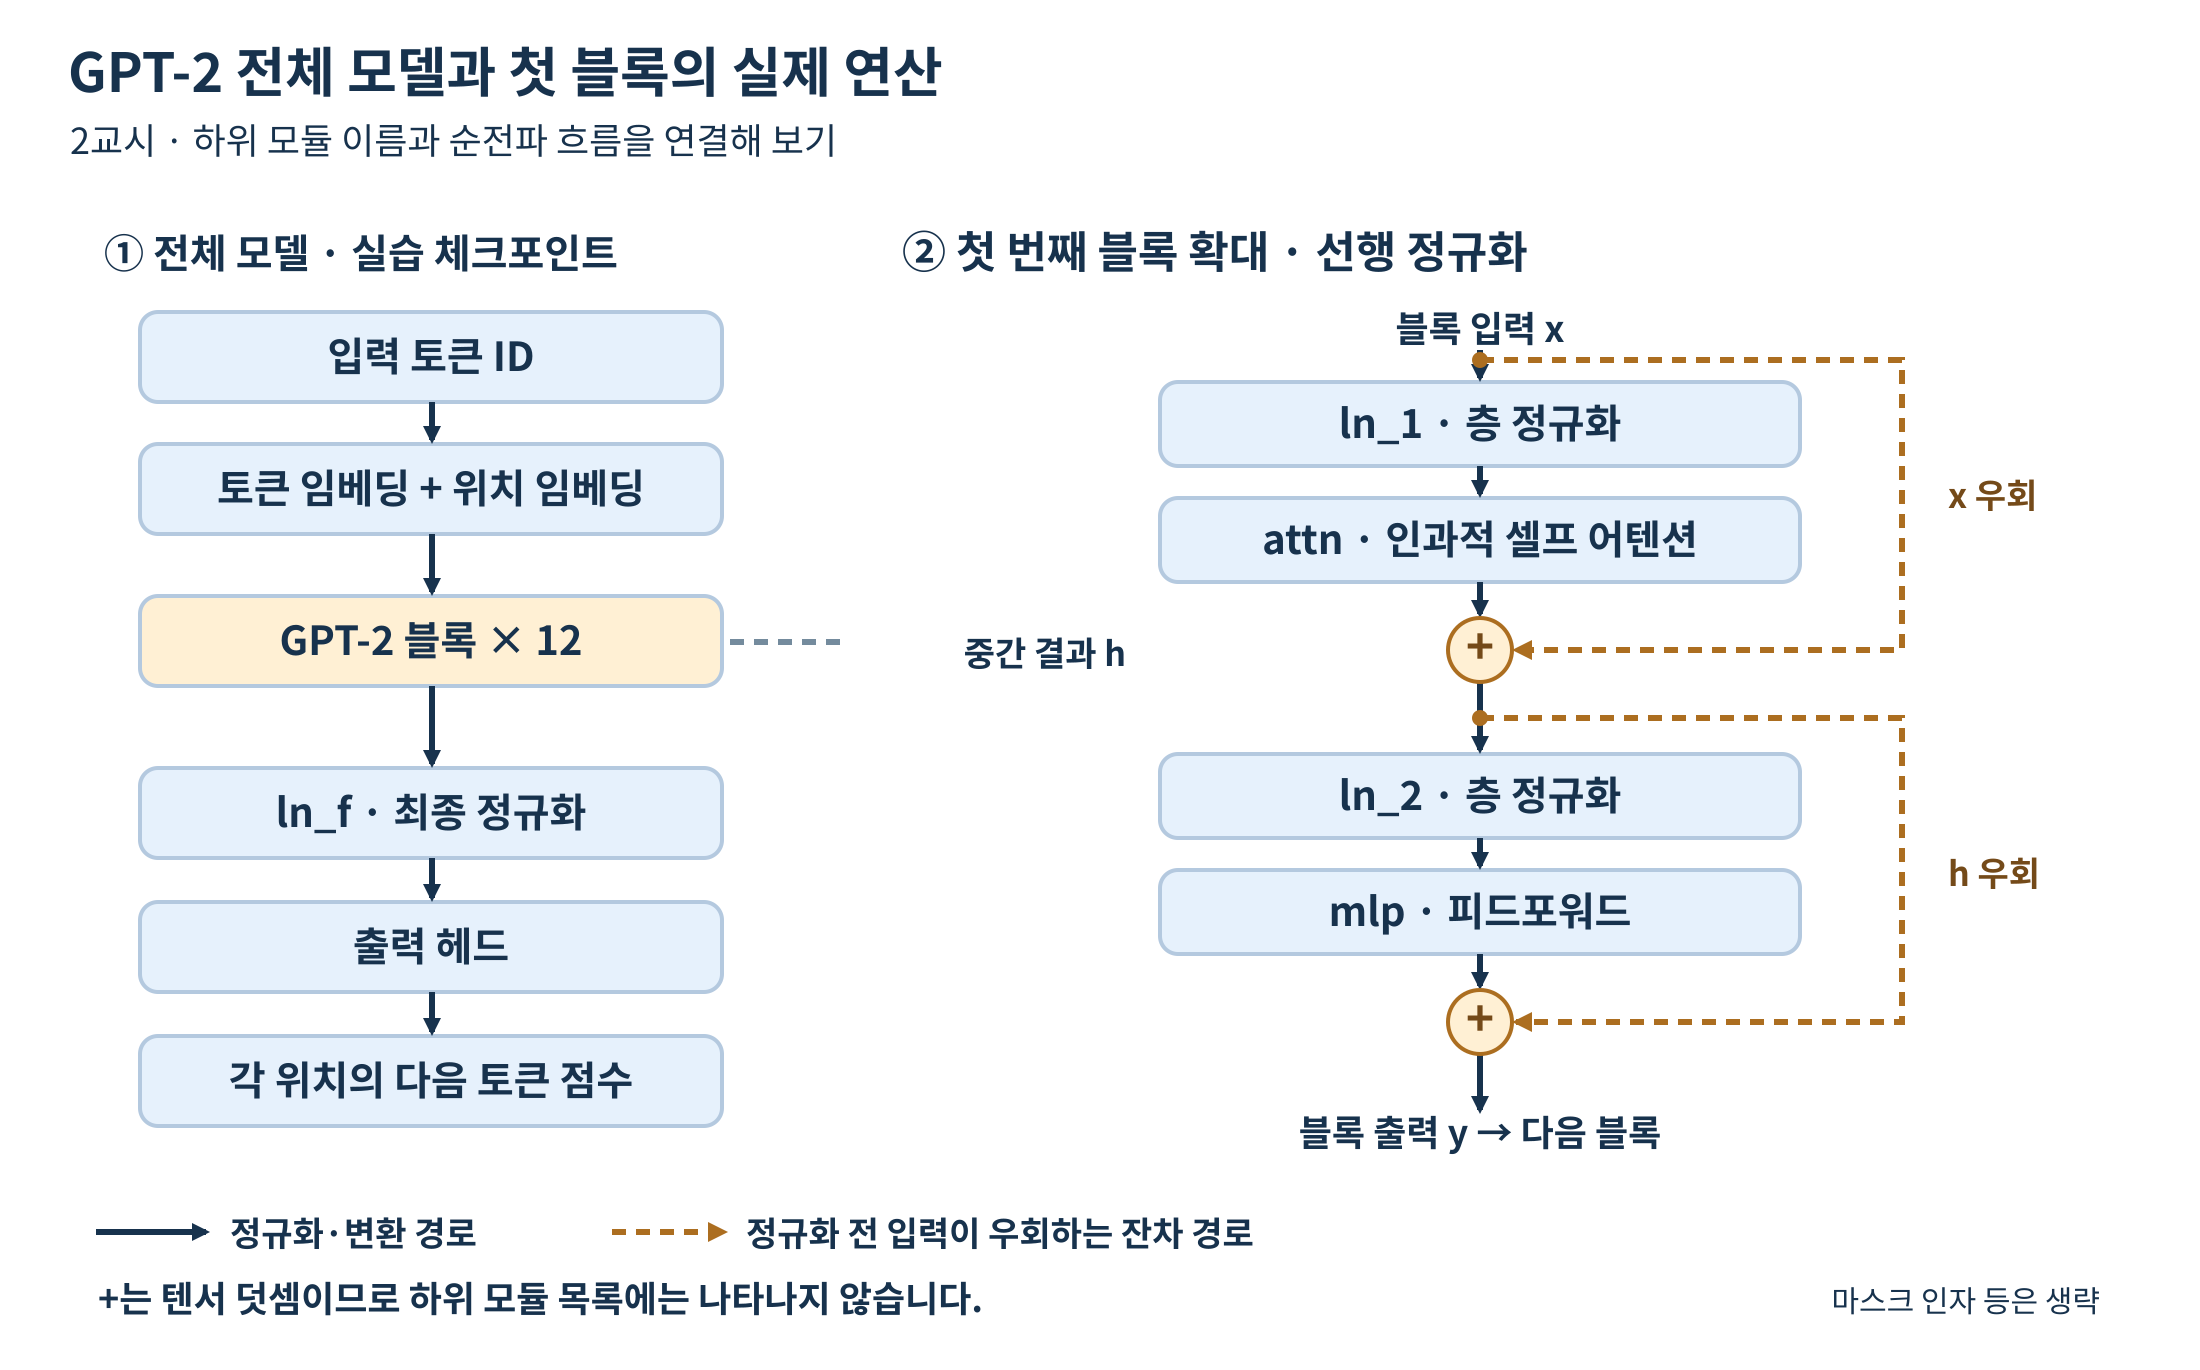

**그림 설명:** 입구에서 토큰 임베딩에 학습한 절대 위치 임베딩을 더합니다. 12개 블록 모두 인과적 MHA와 Dense FFN을 사용합니다.

### Qwen3-4B

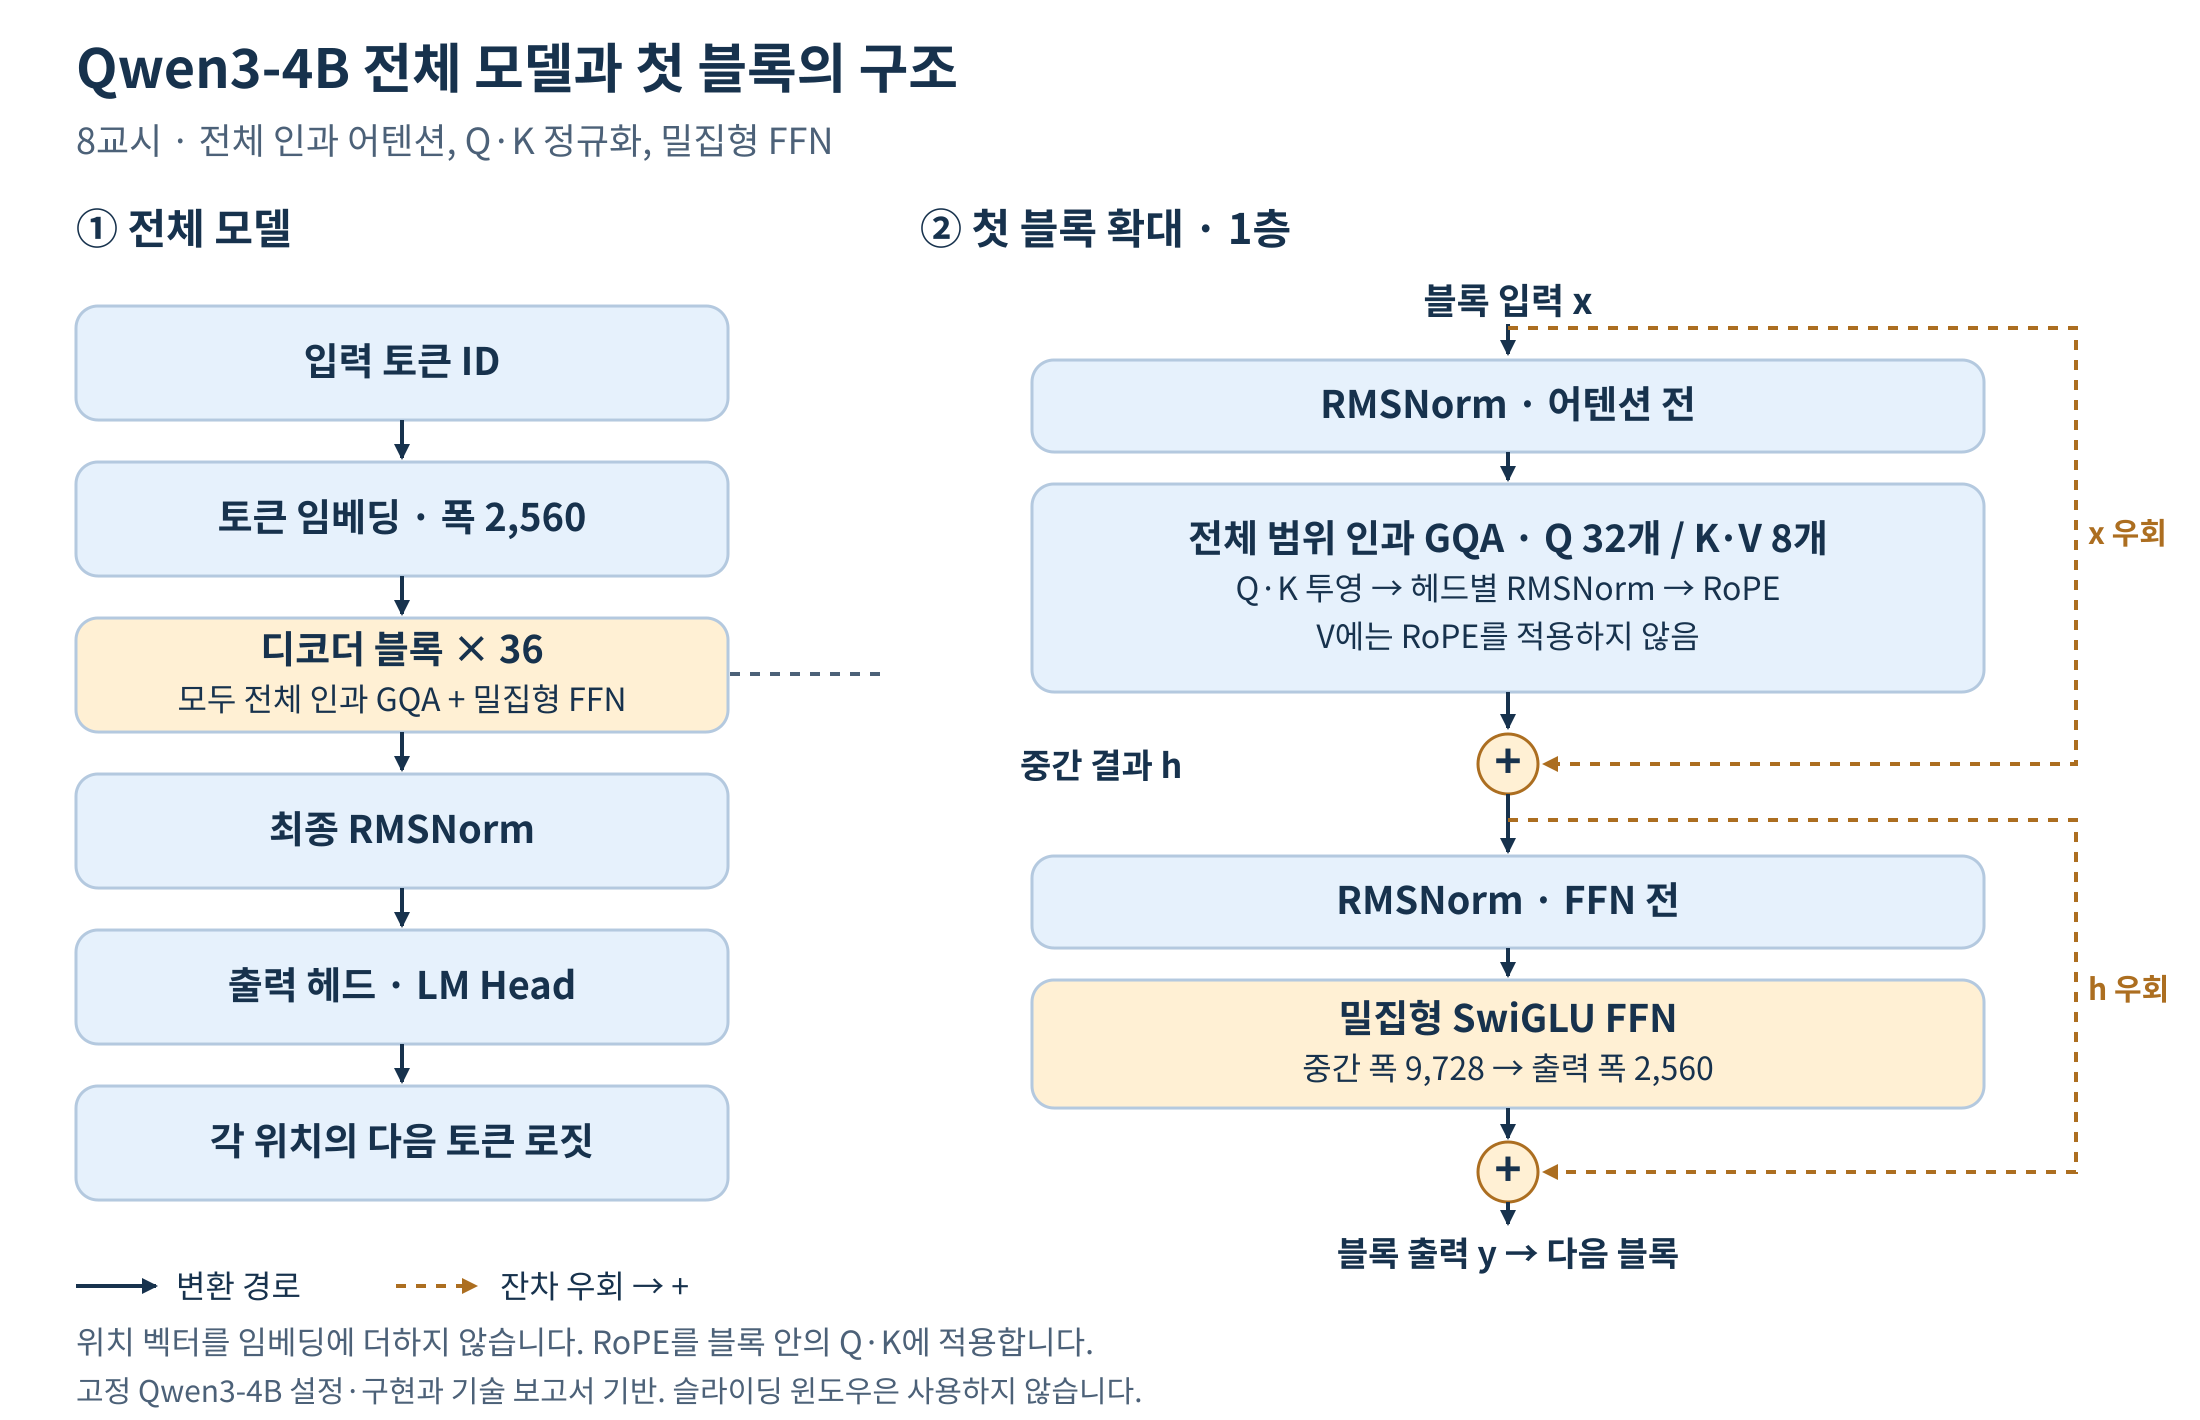

**그림 설명:** 36개 블록의 어텐션 안에서 Q·K에 정규화와 RoPE를 적용합니다. Q 32개가 KV 8쌍을 공유하고, FFN은 이 체크포인트에서 모두 Dense입니다.

### DeepSeek-V3

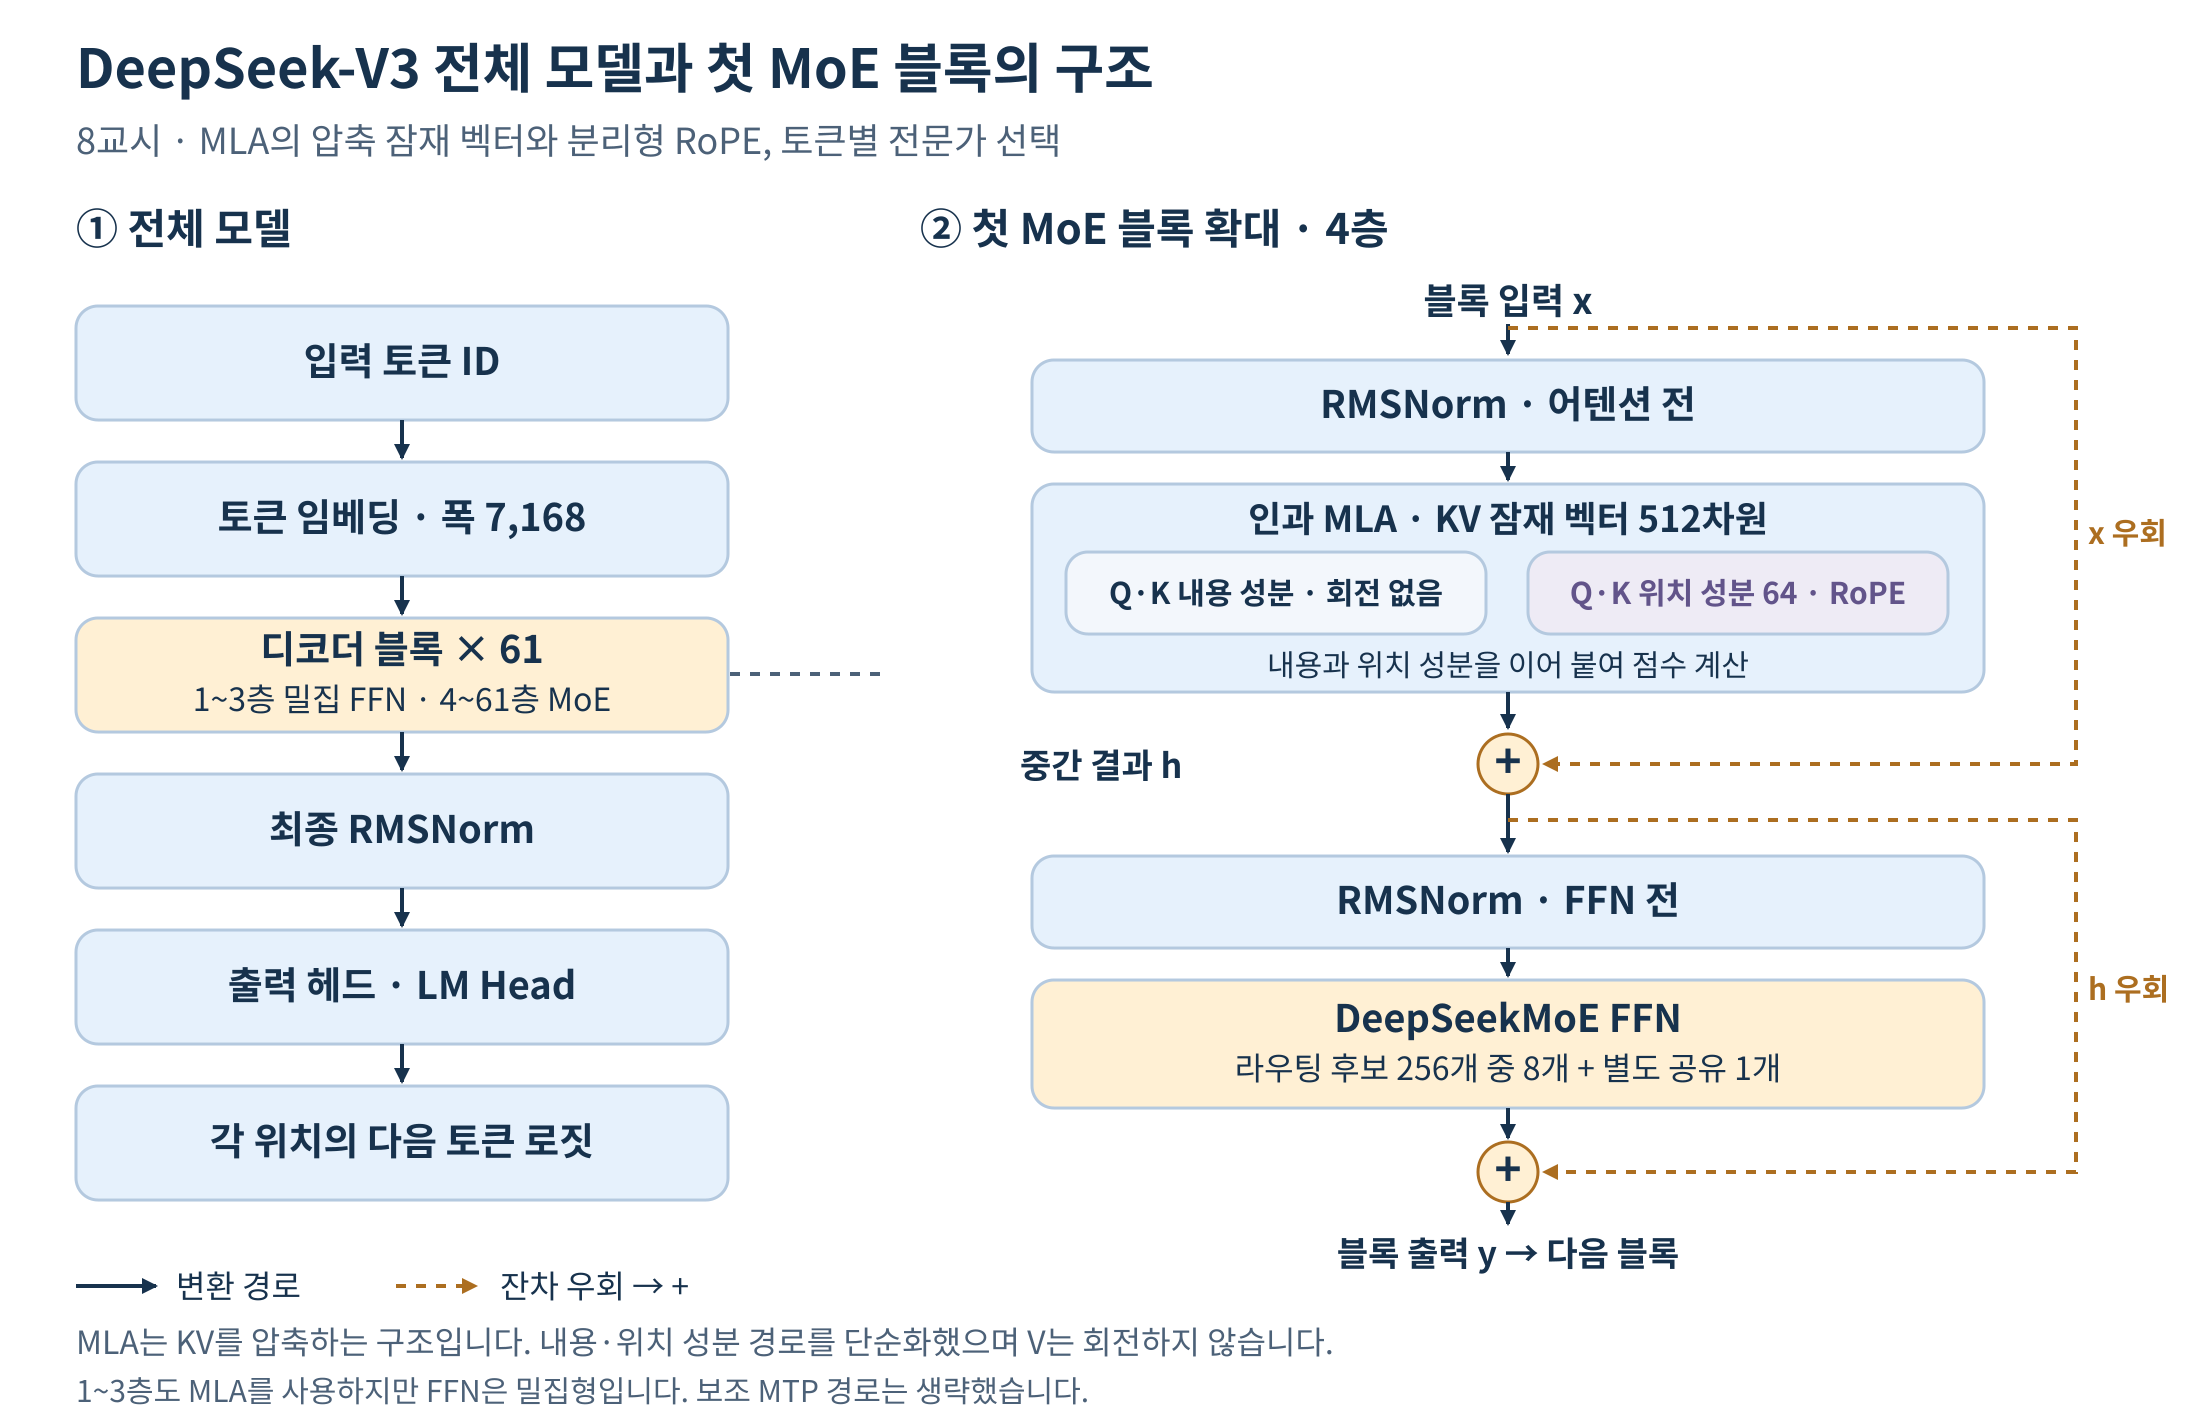

**그림 설명:** 본체 61층 모두 MLA를 사용합니다. RoPE는 Q·K의 위치 전용 성분에 들어갑니다. FFN은 첫 3층이 Dense, 뒤 58층이 MoE입니다.

### K-EXAONE-236B-A23B

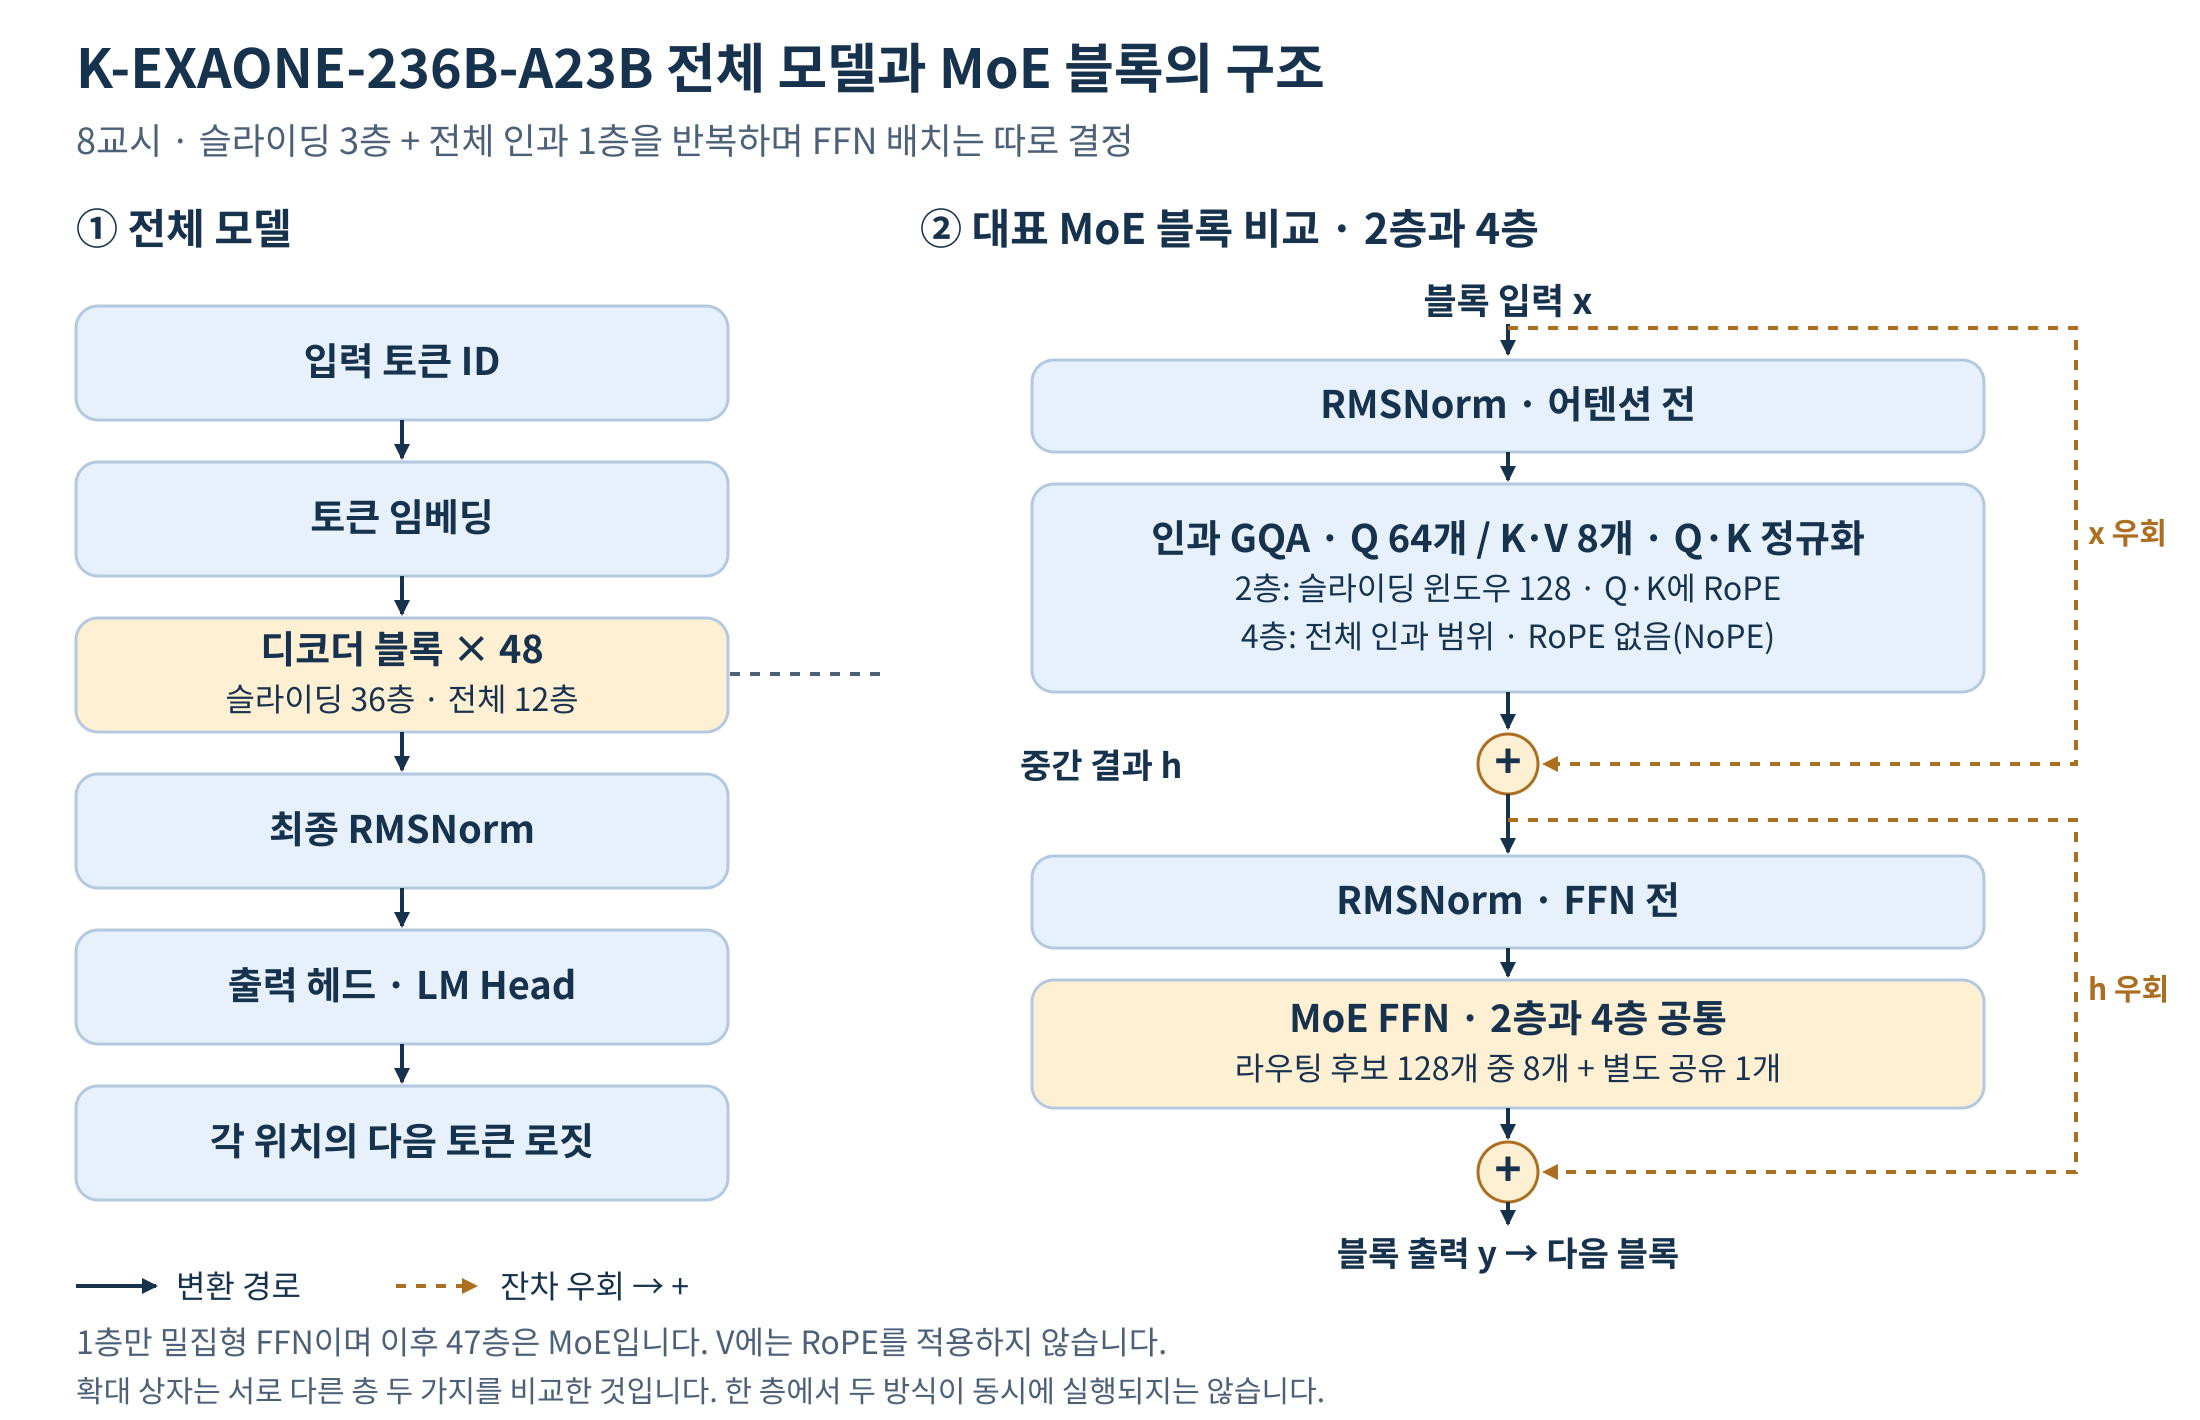

**그림 설명:** 본체 48층에서 슬라이딩 윈도우 3층과 전체 범위 1층이 반복됩니다. RoPE는 슬라이딩 윈도우 층에만 적용합니다. 첫 블록은 Dense, 나머지는 MoE입니다.

그림은 설정과 공식 구현·보고서를 연결한 구조도입니다. 이 교시에서는 모델 가중치를 불러오거나 그림의 순전파를 실행하지 않았습니다.


## 5. 더 읽기: K-EXAONE은 버전이 올라가며 무엇이 달라졌을까요?

8교시의 실습 대상은 **K-EXAONE-236B-A23B**입니다. 아래에서는 후속 모델을 예로 들어 같은 계열에서도 무엇을 유지하고 무엇을 바꿀 수 있는지 살펴봅니다. **2.0·2.5는 이 교시의 실행 대상이 아니며**, 실습 코드와 출력은 기존 네 체크포인트만 비교합니다.

### 모델 공개, 기술보고서 공개, API 개방을 구분합니다

| 시점 | 공개된 것 | 이 절에서 확인하는 근거 |
|---|---|---|
| **2025.12.31 / 2026.01.05** | K-EXAONE-236B-A23B 모델 공개 / 기술보고서 첫 게시(1월 9일 개정) | [공식 공개 기록](https://github.com/LG-AI-EXAONE/K-EXAONE#news) · [보고서 이력](https://arxiv.org/abs/2601.01739) |
| **2026.07.31 / 2026.08.05** | K-EXAONE 2.0 750B-A37B 모델 공개 / 기술보고서 첫 게시 | [공식 공개 기록](https://github.com/LG-AI-EXAONE/K-EXAONE-2.0#news) · [보고서 이력](https://arxiv.org/abs/2608.04505) |
| **2026.11.09** | K-EXAONE 2.5 API 개방 발표 | [LG AI연구원 발표](https://www.lgresearch.ai/news/view?seq=754) · [LG 보도자료](https://lg.co.kr/media/release/30760) |

LG AI연구원은 **2.5를 2차 모델에 추가 학습을 적용한 기술 검증 모델**이라고 설명합니다. [공식 API 문서](https://docs.exaone.ai/en/docs/models)에는 텍스트 모델, 전체 750B·활성 31B, 최대 문맥 512K로 안내됩니다. 이 수치로부터 층이나 라우터의 배치를 역으로 알아낼 수는 없습니다. 공개 발표는 API 접근과 추가 학습을 확인해 주지만, **2.5의 층 수·전문가 수·어텐션 배치를 제시하지 않습니다.** API를 공개했다는 말이 해당 모델의 가중치나 `config.json`까지 공개했다는 뜻은 아닙니다. 아래 구조 비교는 두 버전의 공식 설정과 보고서로 확인할 수 있는 **236B와 2.0**에 한정합니다.

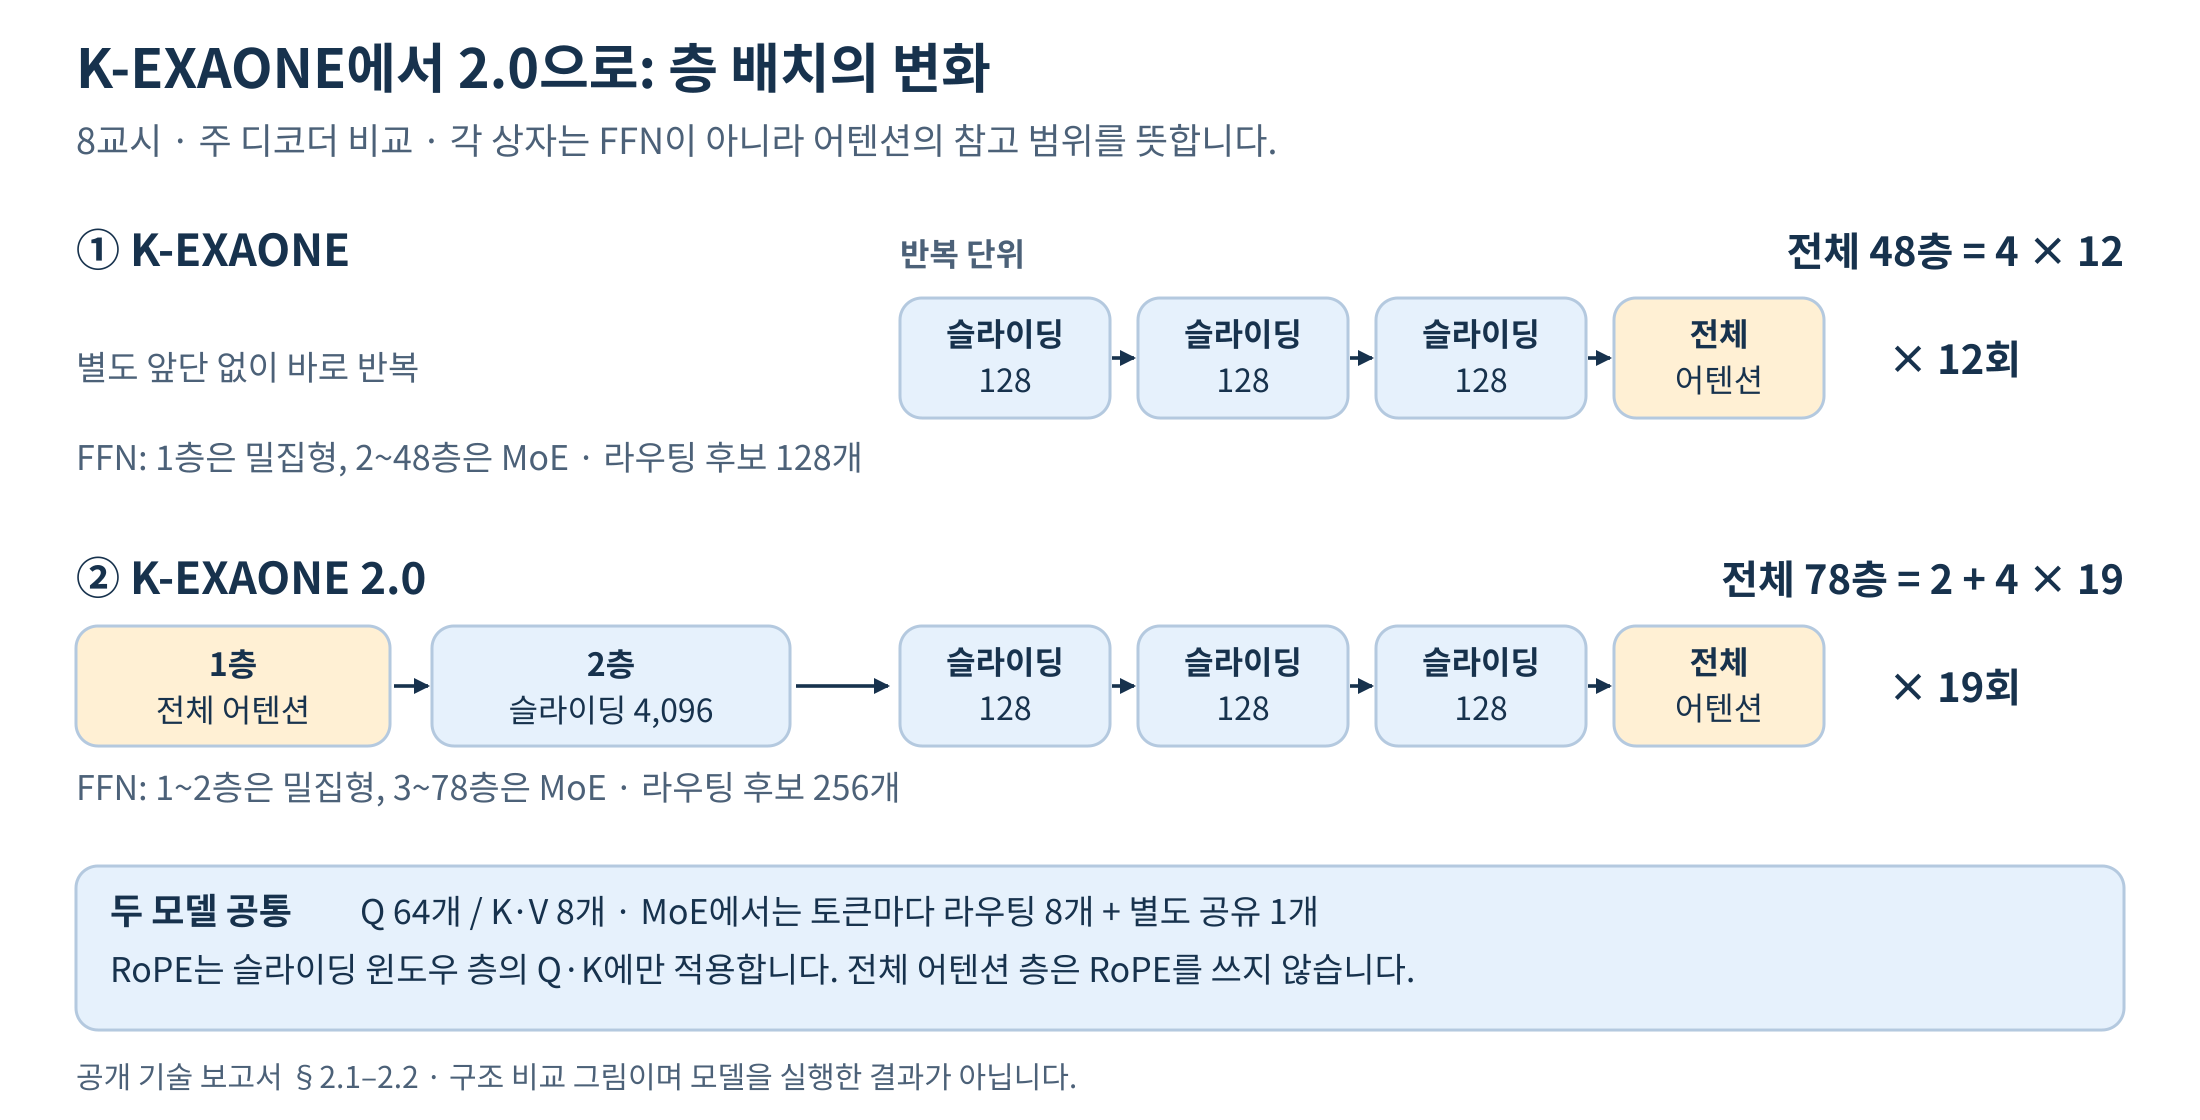

**그림 설명:** 2.0의 첫 두 층은 반복 묶음에 포함되지 않습니다. 첫 층은 전체 범위, 둘째 층은 4,096 위치 슬라이딩 윈도우입니다. 뒤에는 기존의 4층 패턴이 19번 반복됩니다. 어텐션의 참조 범위와 FFN의 Dense·MoE 구분은 각각 따로 읽습니다.

### 더 깊게 쌓고 후보를 늘려도, 한 층에서 고르는 수는 그대로입니다

| 비교 축 | **K-EXAONE-236B-A23B** | **K-EXAONE 2.0 750B-A37B** |
|---|---|---|
| 본체 층 수 | 48층: 첫 1층 Dense, 이후 47층 MoE | 78층: 처음 2층 Dense, 이후 76층 MoE |
| 어텐션 배치 | `LLLG` × 12. 슬라이딩 36층, 전체 범위 12층 | 처음 `G → L(4,096)` 뒤 `LLLG` × 19. 슬라이딩 58층, 전체 범위 20층 |
| 슬라이딩 윈도우 | 슬라이딩 층마다 128토큰 | **본체의 두 번째 층만 4,096토큰**, 나머지 슬라이딩 층은 128토큰 |
| GQA와 위치 정보 | Q 64개 / K·V 각 8개, 헤드당 128차원. QK Norm, 슬라이딩 층에만 RoPE | 동일. 슬라이딩 층에만 RoPE를 쓰고 전체 범위 층에는 적용하지 않습니다. |
| MoE 층의 전문가 | 라우팅 후보 128개 중 토큰당 **8개** 선택, 별도 공유 전문가 **1개** | 라우팅 후보 256개 중 토큰당 **8개** 선택, 별도 공유 전문가 **1개**. 전문가 하나의 중간 폭은 양쪽 모두 2,048입니다. |
| 모델 파라미터 수(보고서 표기) | 전체 236B / 토큰당 활성 23B | 전체 750B / 토큰당 활성 37B |

`L`은 슬라이딩 윈도우 층, `G`는 전체 범위 층입니다. **둘 다 인과적 어텐션**이므로 미래 토큰은 읽지 않습니다. `L`의 숫자는 한 층의 직접 참고 범위이지 모델 전체의 문맥 길이가 아닙니다. 표의 층 수는 본체만 셌으며, MTP나 DSpark 같은 보조 모듈은 합하지 않았습니다. 근거: [원본 고정 설정](https://huggingface.co/LGAI-EXAONE/K-EXAONE-236B-A23B/blob/61e6d578eb102b578e5704e2916ac841df9eca0a/config.json)과 [보고서 §2.1](https://arxiv.org/html/2601.01739v2#S2.SS1), [2.0 고정 설정](https://huggingface.co/LGAI-EXAONE/K-EXAONE-2.0-750B-A37B/blob/b159206982abe02813dae76f0bd568dbd3d4f53f/config.json)과 [보고서 §§2.1–2.2](https://arxiv.org/html/2608.04505#S2).

**여기서 업사이클링(upcycling)은 학습된 모델을 출발점으로 더 큰 모델을 만들고 훈련을 이어가는 방법**입니다. 2.0에서는 기존 본체 중간의 4층 단위 일부를 반복해 깊이를 늘렸습니다. MoE 층에서는 전문가와 각 전문가에 대응하는 라우터 가중치 행을 복제하되, 전문가 복사본에 작은 변화를 주어 같은 계산만 되풀이하지 않도록 한 뒤 사전학습을 이어갔습니다. 이때 늘어난 ‘폭’은 **전문가 후보 수**입니다. 전문가 하나의 중간 폭이나 토큰마다 고르는 수를 두 배로 늘렸다는 뜻은 아닙니다. [2.0 보고서 §2.2](https://arxiv.org/html/2608.04505#S2.SS2)

**4교시 SwiGLU와 연결하면**, 2.0은 마지막 16개 MoE 층에만 Clamped SwiGLU를 적용했습니다. 고정 설정의 `swiglu_limits`에서 이 층들에 해당하는 항목이 `7.0`입니다. 두 분기의 값을 성분별로 제한한 뒤 결합해 깊은 층의 지나치게 큰 활성값을 억제하는 조치입니다. 이때 전문가를 고르는 라우터 규칙을 바꾼 것은 아닙니다. [2.0 고정 설정](https://huggingface.co/LGAI-EXAONE/K-EXAONE-2.0-750B-A37B/blob/b159206982abe02813dae76f0bd568dbd3d4f53f/config.json) · [보고서 §2.2, Training stability](https://arxiv.org/html/2608.04505#S2.SS2.SSS3)

**판단 연습:** “2.0은 전문가 후보가 두 배이므로 한 토큰이 한 층에서 쓰는 라우팅 전문가 수도 두 배다”라고 말할 수 있을까요? **아닙니다.** 후보는 128개에서 256개로 늘었지만 한 MoE 층의 선택은 8개이고, 공유 1개는 별도입니다. 다만 전체 모델에서는 본체가 더 깊어져 토큰당 활성 파라미터 수가 같지 않습니다. 이 구조만으로 추론 시간이나 GPU 메모리의 변화율을 계산할 수는 없습니다.

**후속 실습 아이디어:** 2.0을 더 다룬다면 공식 설정 파일 두 개만 읽어 본체 층 수, 슬라이딩 윈도우 예외, 후보·선택·공유 전문가 수를 나란히 출력해 보세요. 가중치를 받지 않아도 구조는 비교할 수 있습니다. 2.5를 다룰 때는 구조 분석 대신 API 문서에 공개된 문맥 한도나 도구 호출 기능을 별도 주제로 삼습니다.


## 정리와 자기 점검

1. **두 MoE 모델을 골라** 어텐션 설계가 왜 같지 않은지 말해 보세요.

   **예시 답:** DeepSeek-V3는 KV 정보를 잠재 표현으로 다루는 MLA를 사용하고, K-EXAONE은 GQA와 슬라이딩 3층·전체 1층의 위치 범위 배치를 함께 사용합니다.

   **이유:** MoE는 FFN 전문가 선택에 관한 말이므로 Q·KV 구성이나 어느 위치를 읽을지는 별도로 확인해야 합니다. 두 모델이 모두 MoE라는 사실만으로 어텐션까지 같다고 할 수 없습니다.

2. **K-EXAONE의 한 블록을 골라** “무엇을 읽는가”와 “어느 FFN이 계산하는가”를 분리해 적으세요.

   **예시 답과 이유:** “K-EXAONE의 본체 4번째 층은 전체 어텐션을 쓰고, FFN은 Sparse다. 이는 위치를 보는 범위와 전문가 선택이 별개의 결정임을 보여준다.” 여기서 “전체”는 **인과 마스크 안에서 슬라이딩 윈도우를 쓰지 않는다**는 뜻이지, 미래 토큰을 읽는다는 뜻이 아닙니다.

## 참고 자료

- GPT-2: [OpenAI 보고서 §2.3: 모델 구조](https://cdn.openai.com/better-language-models/language_models_are_unsupervised_multitask_learners.pdf#page=4), [GPT-2 구현](https://github.com/huggingface/transformers/blob/v5.23.0/src/transformers/models/gpt2/modeling_gpt2.py).
- Qwen3: [Qwen3 Technical Report §2: 모델 구조](https://arxiv.org/html/2505.09388#S2). 이 실습은 공식 계열 중 **4B Dense** 체크포인트만 읽습니다.
- DeepSeek: [DeepSeek-V3 Technical Report §2.1: MLA·MoE](https://arxiv.org/html/2412.19437#S2.SS1). MLA와 DeepSeekMoE가 각각 맡는 역할을 확인합니다.
- K-EXAONE: [K-EXAONE Technical Report §2.1: 모델 구조](https://arxiv.org/html/2601.01739v2#S2.SS1). 이 실습은 **236B-A23B** 본체의 층 배치만 읽습니다. 다른 버전이나 보조 예측 층의 수를 합하지 않습니다.

### 공개 설정의 고정 버전
- [openai-community/gpt2 config.json](https://huggingface.co/openai-community/gpt2/blob/607a30d783dfa663caf39e06633721c8d4cfcd7e/config.json)
- [Qwen/Qwen3-4B config.json](https://huggingface.co/Qwen/Qwen3-4B/blob/1cfa9a7208912126459214e8b04321603b3df60c/config.json)
- [deepseek-ai/DeepSeek-V3 config.json](https://huggingface.co/deepseek-ai/DeepSeek-V3/blob/e815299b0bcbac849fa540c768ef21845365c9eb/config.json)
- [LGAI-EXAONE/K-EXAONE-236B-A23B config.json](https://huggingface.co/LGAI-EXAONE/K-EXAONE-236B-A23B/blob/61e6d578eb102b578e5704e2916ac841df9eca0a/config.json)